In [ ]:
# ==============================================================================
# Purpose:
#   Mono-focused CNA + gene-program interpretation:
#     (1) run CNA neighborhood association for race (NHB vs NHW) in Mono cells
#         within each Mono subtype x disease state,
#     (2) correlate per-cell race_coef with gene expression (fast Spearman),
#     (3) run preranked GSEA (Hallmark + ImmPort) on rho,
#     (4) make Figure 6 panels: Mono UMAPs (celltype, race, race_coef) and
#         pathway NES bar panels + per-state bubble plots for selected ImmPort sets.
#
# Steps:
#   1) Set plotting params; load palettes + metadata; map covariates into dat.obs.
#   2) Subset Mono; load saved UMAP coords; compute neighbors.
#   3) Build sample-level table (samplem) with covariates; add batch (Pool137/Pool138).
#   4) Run cna.tl.association for race (return_full=True); save Mono CNA object + full res.
#   5) Define disease_state labels; for each (Mono subtype x disease_state):
#        - run CNA race association; compute Spearman(gene, race_coef); prerank GSEA; save CSVs.
#      Repeat per disease_state for all Mono cells.
#   6) Load overall_Mono CNA; plot UMAPs:
#        - celltype_level3 (renamed to CM/IM/NCM/CyM), race, and race_coef (sig-only).
#   7) Aggregate GSEA CSVs into one table; plot multi-panel barh of NES across subtypes/states
#      for selected pathways; generate bubble plots per disease_state (NES vs term; size=Tag%).
# ==============================================================================

# Header

In [2]:
from utils import *

In [3]:
import sys
sys.path.insert(0, '/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src')
import cna

In [4]:
import gseapy as gp
import scanpy as sc
from itertools import product
from matplotlib.patches import Patch
from textwrap import fill

In [5]:
print(gp.__version__)

1.1.9


In [6]:
os.chdir('../')

In [7]:
import scanpy as sc
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [8]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

In [9]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from scipy import sparse
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

def fast_spearman_ann(adata, obs_key, genes=None, chunk_size=2000, eps=1e-12):
    """
    Fast Spearman correlation between a per-cell variable (obs_key)
    and expression of each gene in adata.
    Returns a DataFrame with columns: rho, pval, fdr.
    """
    if genes is None:
        genes = adata.var_names
    X = adata[:, genes].X
    n_cells, n_genes = X.shape

    # rank-transform the covariate
    c = pd.to_numeric(adata.obs[obs_key], errors='coerce').to_numpy()
    r_c = rankdata(c, method='average')
    r_c0 = r_c - r_c.mean()
    norm_rc0 = np.linalg.norm(r_c0) + eps

    rho = np.empty(n_genes, dtype=float)

    for start in range(0, n_genes, chunk_size):
        end = min(start + chunk_size, n_genes)
        Xi = X[:, start:end]

        if sparse.issparse(Xi):
            Xi = Xi.toarray()

        # rank each gene (column) across cells
        R = np.apply_along_axis(rankdata, 0, Xi, method='average')
        R0 = R - R.mean(axis=0, keepdims=True)
        denomX = np.linalg.norm(R0, axis=0) + eps

        # Pearson on ranks = Spearman
        rho[start:end] = (R0.T @ r_c0) / (norm_rc0 * denomX)

    # --- p-values (two-sided) via t-approximation ---
    df = n_cells - 2
    # Clamp |rho| to < 1 to avoid division by zero
    rho_clamped = np.clip(rho, -1 + 1e-15, 1 - 1e-15)
    t_stat = rho_clamped * np.sqrt(df / (1 - rho_clamped**2))
    pval = 2 * student_t.sf(np.abs(t_stat), df=df)

    # --- FDR (Benjamini–Hochberg) ---
    fdr = multipletests(pval, method='fdr_bh')[1]

    out = pd.DataFrame(
        {'rho': rho, 'pval': pval, 'fdr': fdr},
        index=pd.Index(genes, name='gene')
    )
    out.name = f'spearman_{obs_key}'
    return out

In [10]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

# Load data

In [10]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
#meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)
meta = meta.drop(columns = ['race_stage'])

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,Y,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,Y,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,Y,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [13]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,predicted.celltype.l3,mapping.score,RNA_snn_res.0.8,seurat_clusters,dataset_name,RNA_snn_res.0.1,S.Score,G2M.Score,Phase,celltype_level3
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,CD4 TCM_1,0.827455,0,0,Pool137_10,0,-0.035611,-0.030749,G1,Naive CD4T
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,CD16 Mono,0.740965,5,5,Pool137_10,5,0.004613,0.004461,S,Nonclassical Monocyte
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,CD8 Naive,0.874696,6,6,Pool137_10,6,0.027257,-0.066766,S,Naive CD8T
Pool137_10_AAACCTGAGCTGCGAA-1,1033.0,1033,2685.0,104.0,3.873371,0.053408,2685.0,1033.0,3.873371,0.990250,...,CD4 TCM_1,0.842401,0,0,Pool137_10,0,-0.049705,0.004598,G2M,Naive CD4T
Pool137_10_AAACCTGAGGACACCA-1,2518.0,2515,6370.0,189.0,2.967033,0.012493,6370.0,2515.0,2.967033,1.000000,...,CD16 Mono,0.836383,5,5,Pool137_10,5,0.003770,-0.014496,S,Nonclassical Monocyte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1309.0,1308,2604.0,43.0,1.651306,0.026204,2604.0,1308.0,1.651306,1.000000,...,CD14 Mono,0.925401,2,1,Pool138_9,1,0.128049,0.014490,S,Classical Monocyte
Pool138_9_TTTGTCATCCTAGGGC-1,1464.0,1464,3533.0,41.0,1.160487,0.105614,3533.0,1464.0,1.160487,1.000000,...,CD4 TCM_3,0.890462,5,0,Pool138_9,0,0.020027,-0.014519,S,Effector Memory CD4T
Pool138_9_TTTGTCATCGCACTCT-1,1310.0,1310,3125.0,56.0,1.792000,0.020296,3125.0,1310.0,1.792000,1.000000,...,CD4 TCM_1,0.842334,1,0,Pool138_9,0,-0.052514,-0.009035,G1,Naive CD4T
Pool138_9_TTTGTCATCTAACTGG-1,1774.0,1774,5072.0,107.0,2.109622,0.085158,5072.0,1774.0,2.109621,1.000000,...,CD4 TCM_1,0.824522,1,0,Pool138_9,0,-0.042068,0.002366,G2M,Naive CD4T


In [14]:
for col in ['age', 'race-stage', 'race', 'group', 'diabetes', 'obesity']:
    dat.obs[col] = dat.obs['dataset_name'].map(meta.set_index('dataset_name')[col])
    
for xcol in ['diabetes','obesity']:
    dat.obs[xcol] = [1 if x=='Y' else 0 for x in dat.obs[xcol]]

xcol = 'group'
dat.obs[xcol] = [0 if x=='HRL' else 1 if x=='DCIS' else 2 for x in dat.obs[xcol]]

xcol = 'race'
dat.obs[xcol] = [0 if x=='NHW' else 1 if x=='NHB' else None for x in dat.obs[xcol]]

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race',
       'group', 'diabetes', 'obesity'],
      dtype='object')

In [15]:
celltype_major = 'Mono'

In [16]:
d = dat[
    dat.obs['predicted.celltype.l1'] == celltype_major
]
d

View of AnnData object with n_obs × n_vars = 108864 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.stand

In [17]:
umap = pd.read_csv(f"data/03_cleandata/ft_{celltype_major}_UmapCoords.csv",
                   index_col=2
                  ).loc[d.obs.index,:]

d.obsm['X_umap'] = umap.values

/tmp/ipykernel_3382217/3805644948.py:5: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  d.obsm['X_umap'] = umap.values


# Calc

In [18]:
len(d.obs['dataset_name'].unique())

55

## Disease state

In [23]:
d.obs['disease_state'] = ['HRL' if x==0 else 'DCIS' if x==1 else 'BC' if x==2 else None for x in d.obs['group']]

Counter(d.obs['disease_state'])

Counter({'BC': 47388, 'HRL': 45508, 'DCIS': 15968})

In [25]:
for group in ['HRL','DCIS','BC']:
    
    d_sub = d[
    (d.obs['disease_state']==group)
    ]

    sc.pp.neighbors(d_sub)

    covars = ['race', 'age']
    for v in ['obesity', 'diabetes']:
        if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
            covars.append(v)
            
    samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                   covars,     # the metadata columns to use
                                   'dataset_name')                        # the column of d.obs that contains sample IDs
    
    samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
    
    
    res = cna.tl.association(
        d_sub,
        samplem.race, 
        'dataset_name',
        covs=samplem[[c for c in covars if c != 'race']],
        batches=samplem.batch,
        key_added='race_coef',
        return_full=True
    )

    res = fast_spearman_ann(d_sub, 
                        obs_key='race_coef', 
                        genes=d_sub.var_names, chunk_size=2000)

    gene_corr_df = pd.DataFrame(res)
    

    pre_res2 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/immport_allgenelist.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d

    # pre_res1.to_csv(f'data/Figure6/CNArankNHBvsW_Mono_{group}_hallmark.csv')
    pre_res2.to_csv(f'data/Figure5/CNArankNHBvsW_Mono_{group}_immport.csv')
    print(f'Done for {group}')


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
2026-06-23 14:26:35,832 [WARNING] Duplicated values found in preranked stats: 8.55% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:26:35,835 [INFO] Parsing data files for GSEA................

Done for HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
2026-06-23 14:29:58,153 [WARNING] Duplicated values found in preranked stats: 15.98% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:29:58,161 [INFO] Parsing data files for GSEA.............................
2026-06-23 14:29:58,348 [INFO] 0035 gene_sets have been filtered out when max_size=1000 and min_size=5
2026-06-23 14:29:58,354 [INFO] 0118 gene_sets used for further statistical testing.....
2026-06-23 14:29:58,357 [INFO] Start to run GSEA...Might take a while..................
2026-06-23 14:30:56,393 [INFO] Congratulations

Done for DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:87: UserWarning: global association p-value attained minimal possible value. Consider increasing Nnull
  warnings.warn('global association p-value attained minimal possible value. '+\
2026-06-23 14:40:34,069 [WARNING] Duplicated values found in preranked stats: 11.43% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:40:34,079 [INFO] Parsing data files for GSEA.............................
2026-06-23 14:40:34,279 [INF

Done for BC


# Analysis

## Overall

In [10]:
with open('data/10_cna/overall_Mono.pkl','rb') as f:
    d = pkl.load(f)

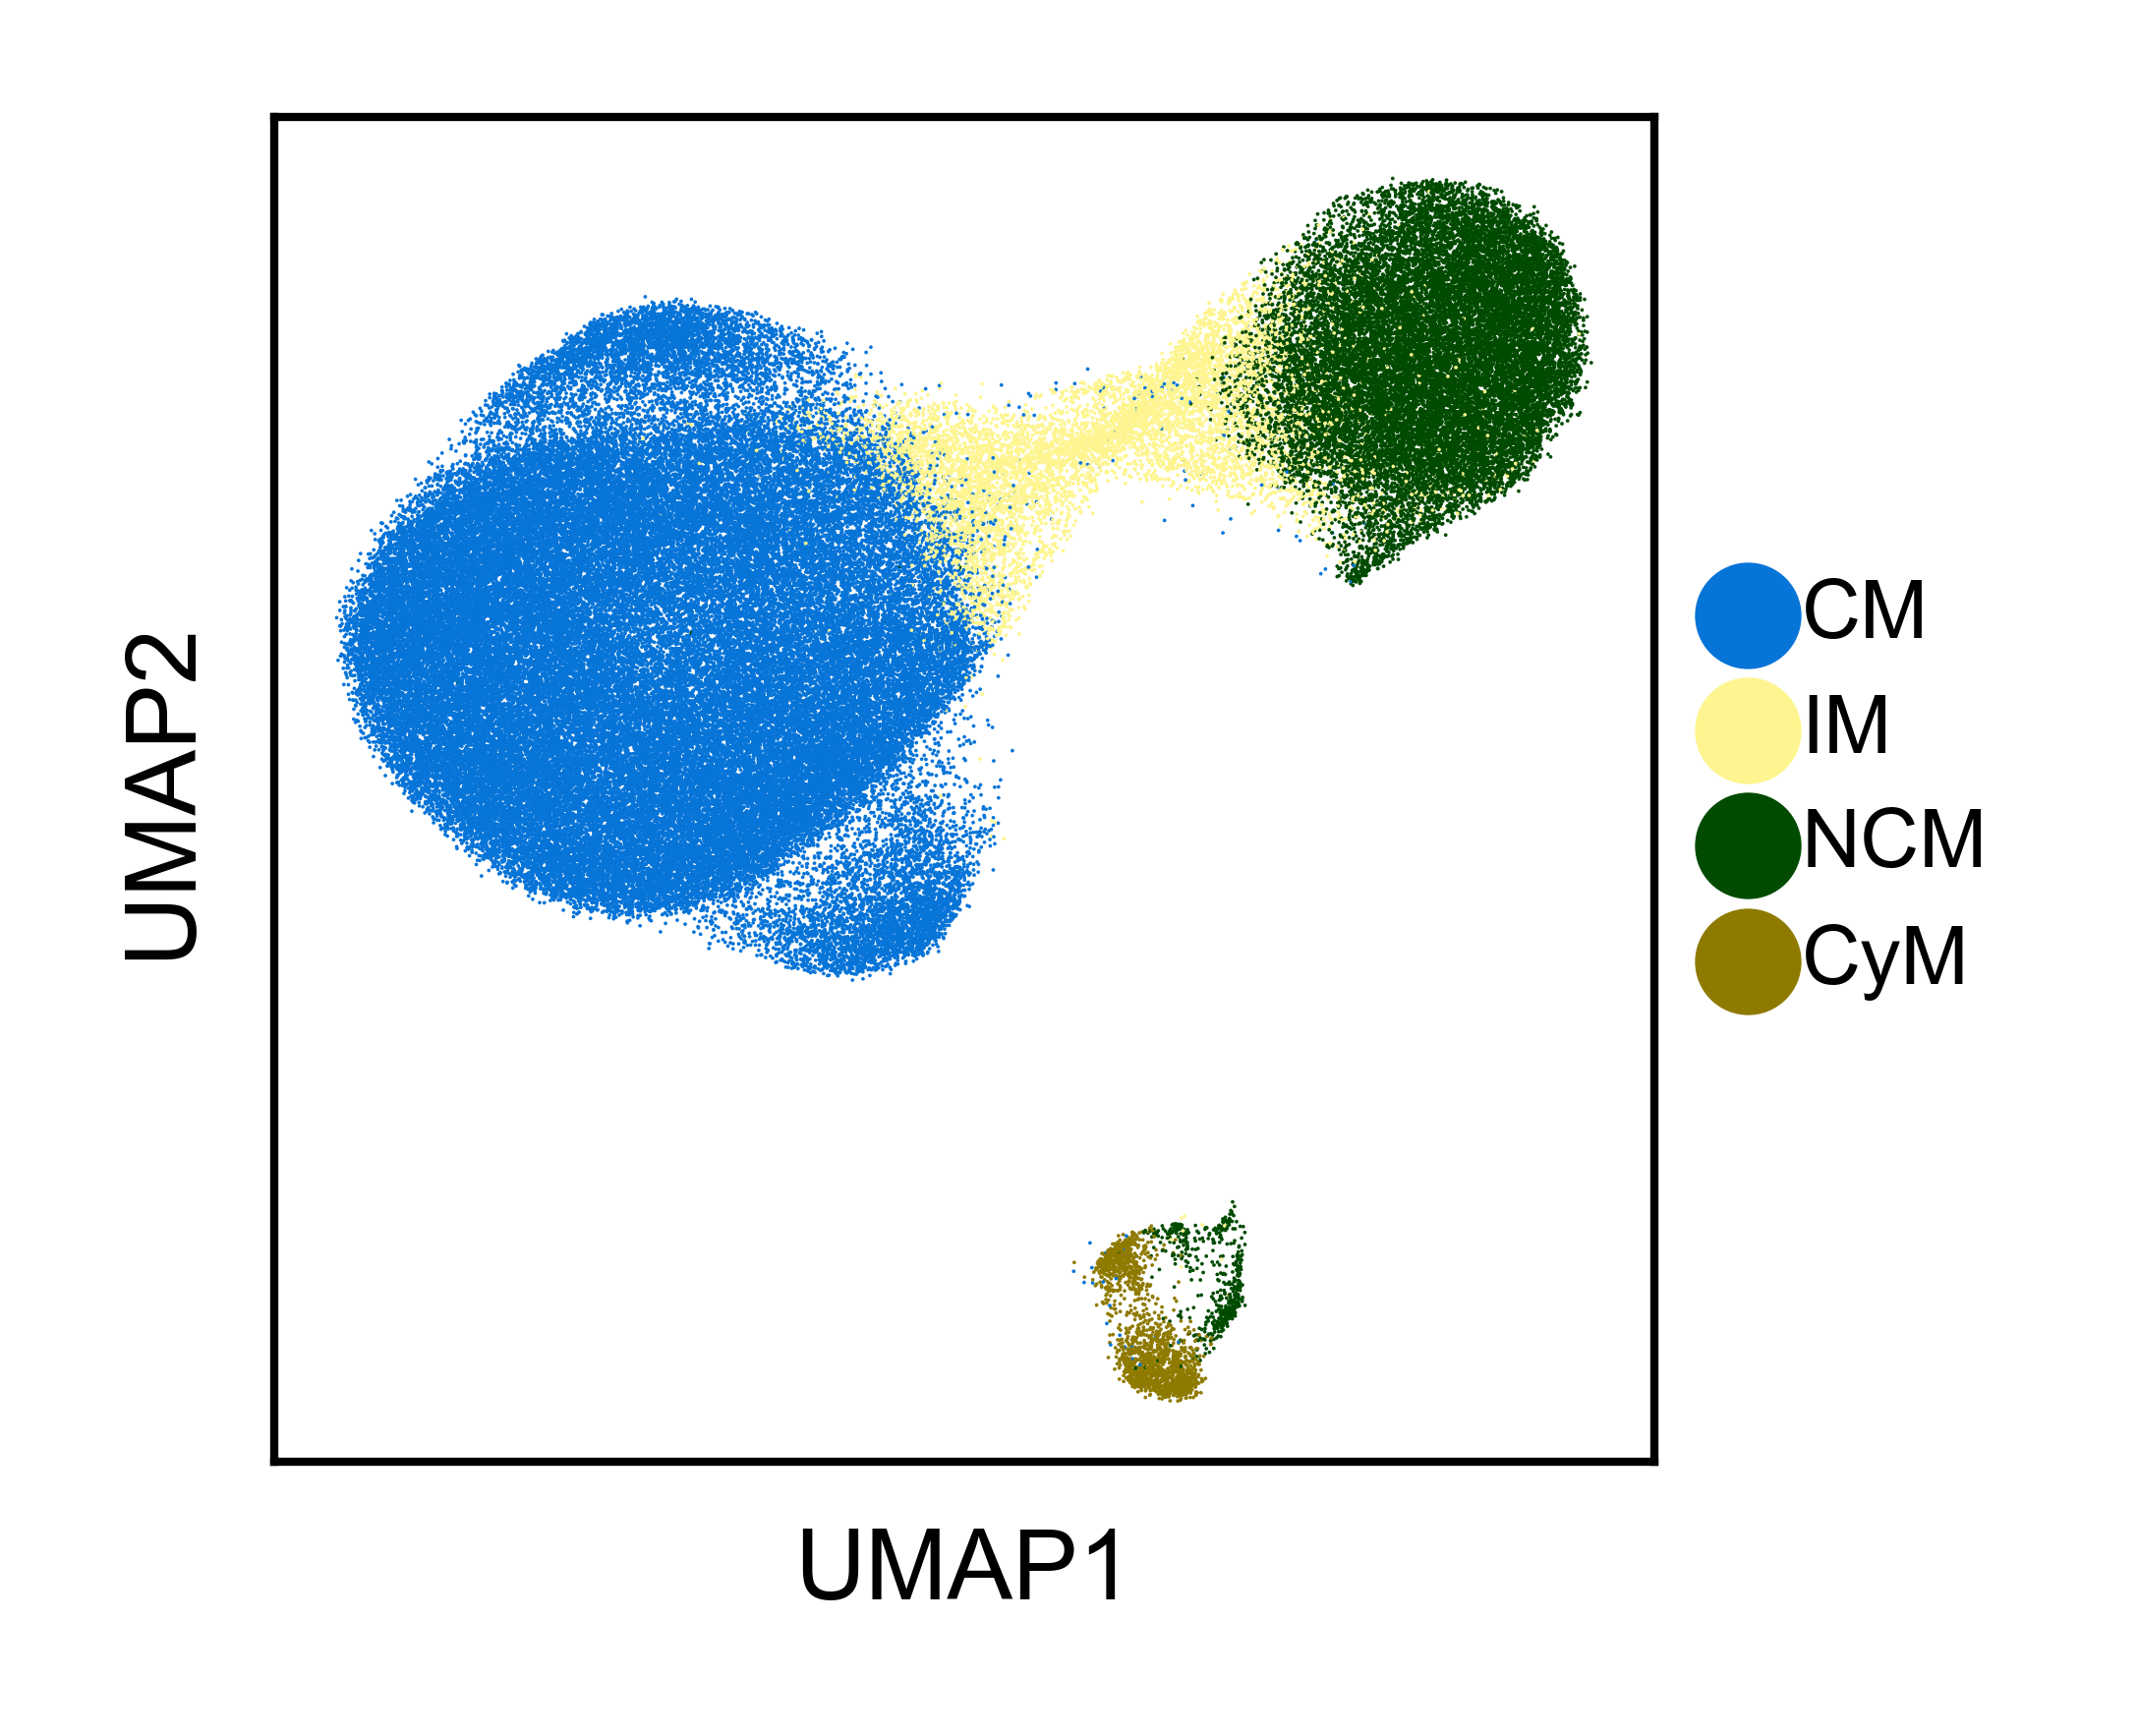

In [10]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'celltype_level3'
# cell_colors = {x: palsamplem['race-stage'] = samplem.apply(lambda row: f"{row['race']}-{row['group']}", axis=1)
# Counter(samplem['race-stage'])
#palette[ct] = (0.8, 0.8, 0.8)

order = cells_group['Mono']
pal_ordered = [palette_all[c] for c in order]

newlabel_dict = {
'Classical Monocyte': 'CM', 
'Intermediate Monocyte': 'IM', 
'Nonclassical Monocyte': 'NCM', 
'Cytotoxic Monocyte': 'CyM'
}

d.obs['celltype_level3_new'] = [
    newlabel_dict[x] for x in d.obs['celltype_level3']
]

d.obs['celltype_level3_new'] = pd.Categorical(
    d.obs['celltype_level3_new'],
    categories=[newlabel_dict[x] for x in order],
    ordered=True
)


sc.pl.umap(
    d,
    color='celltype_level3_new',
    palette=pal_ordered,
    size=.2,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6/Mono_celltype.svg')

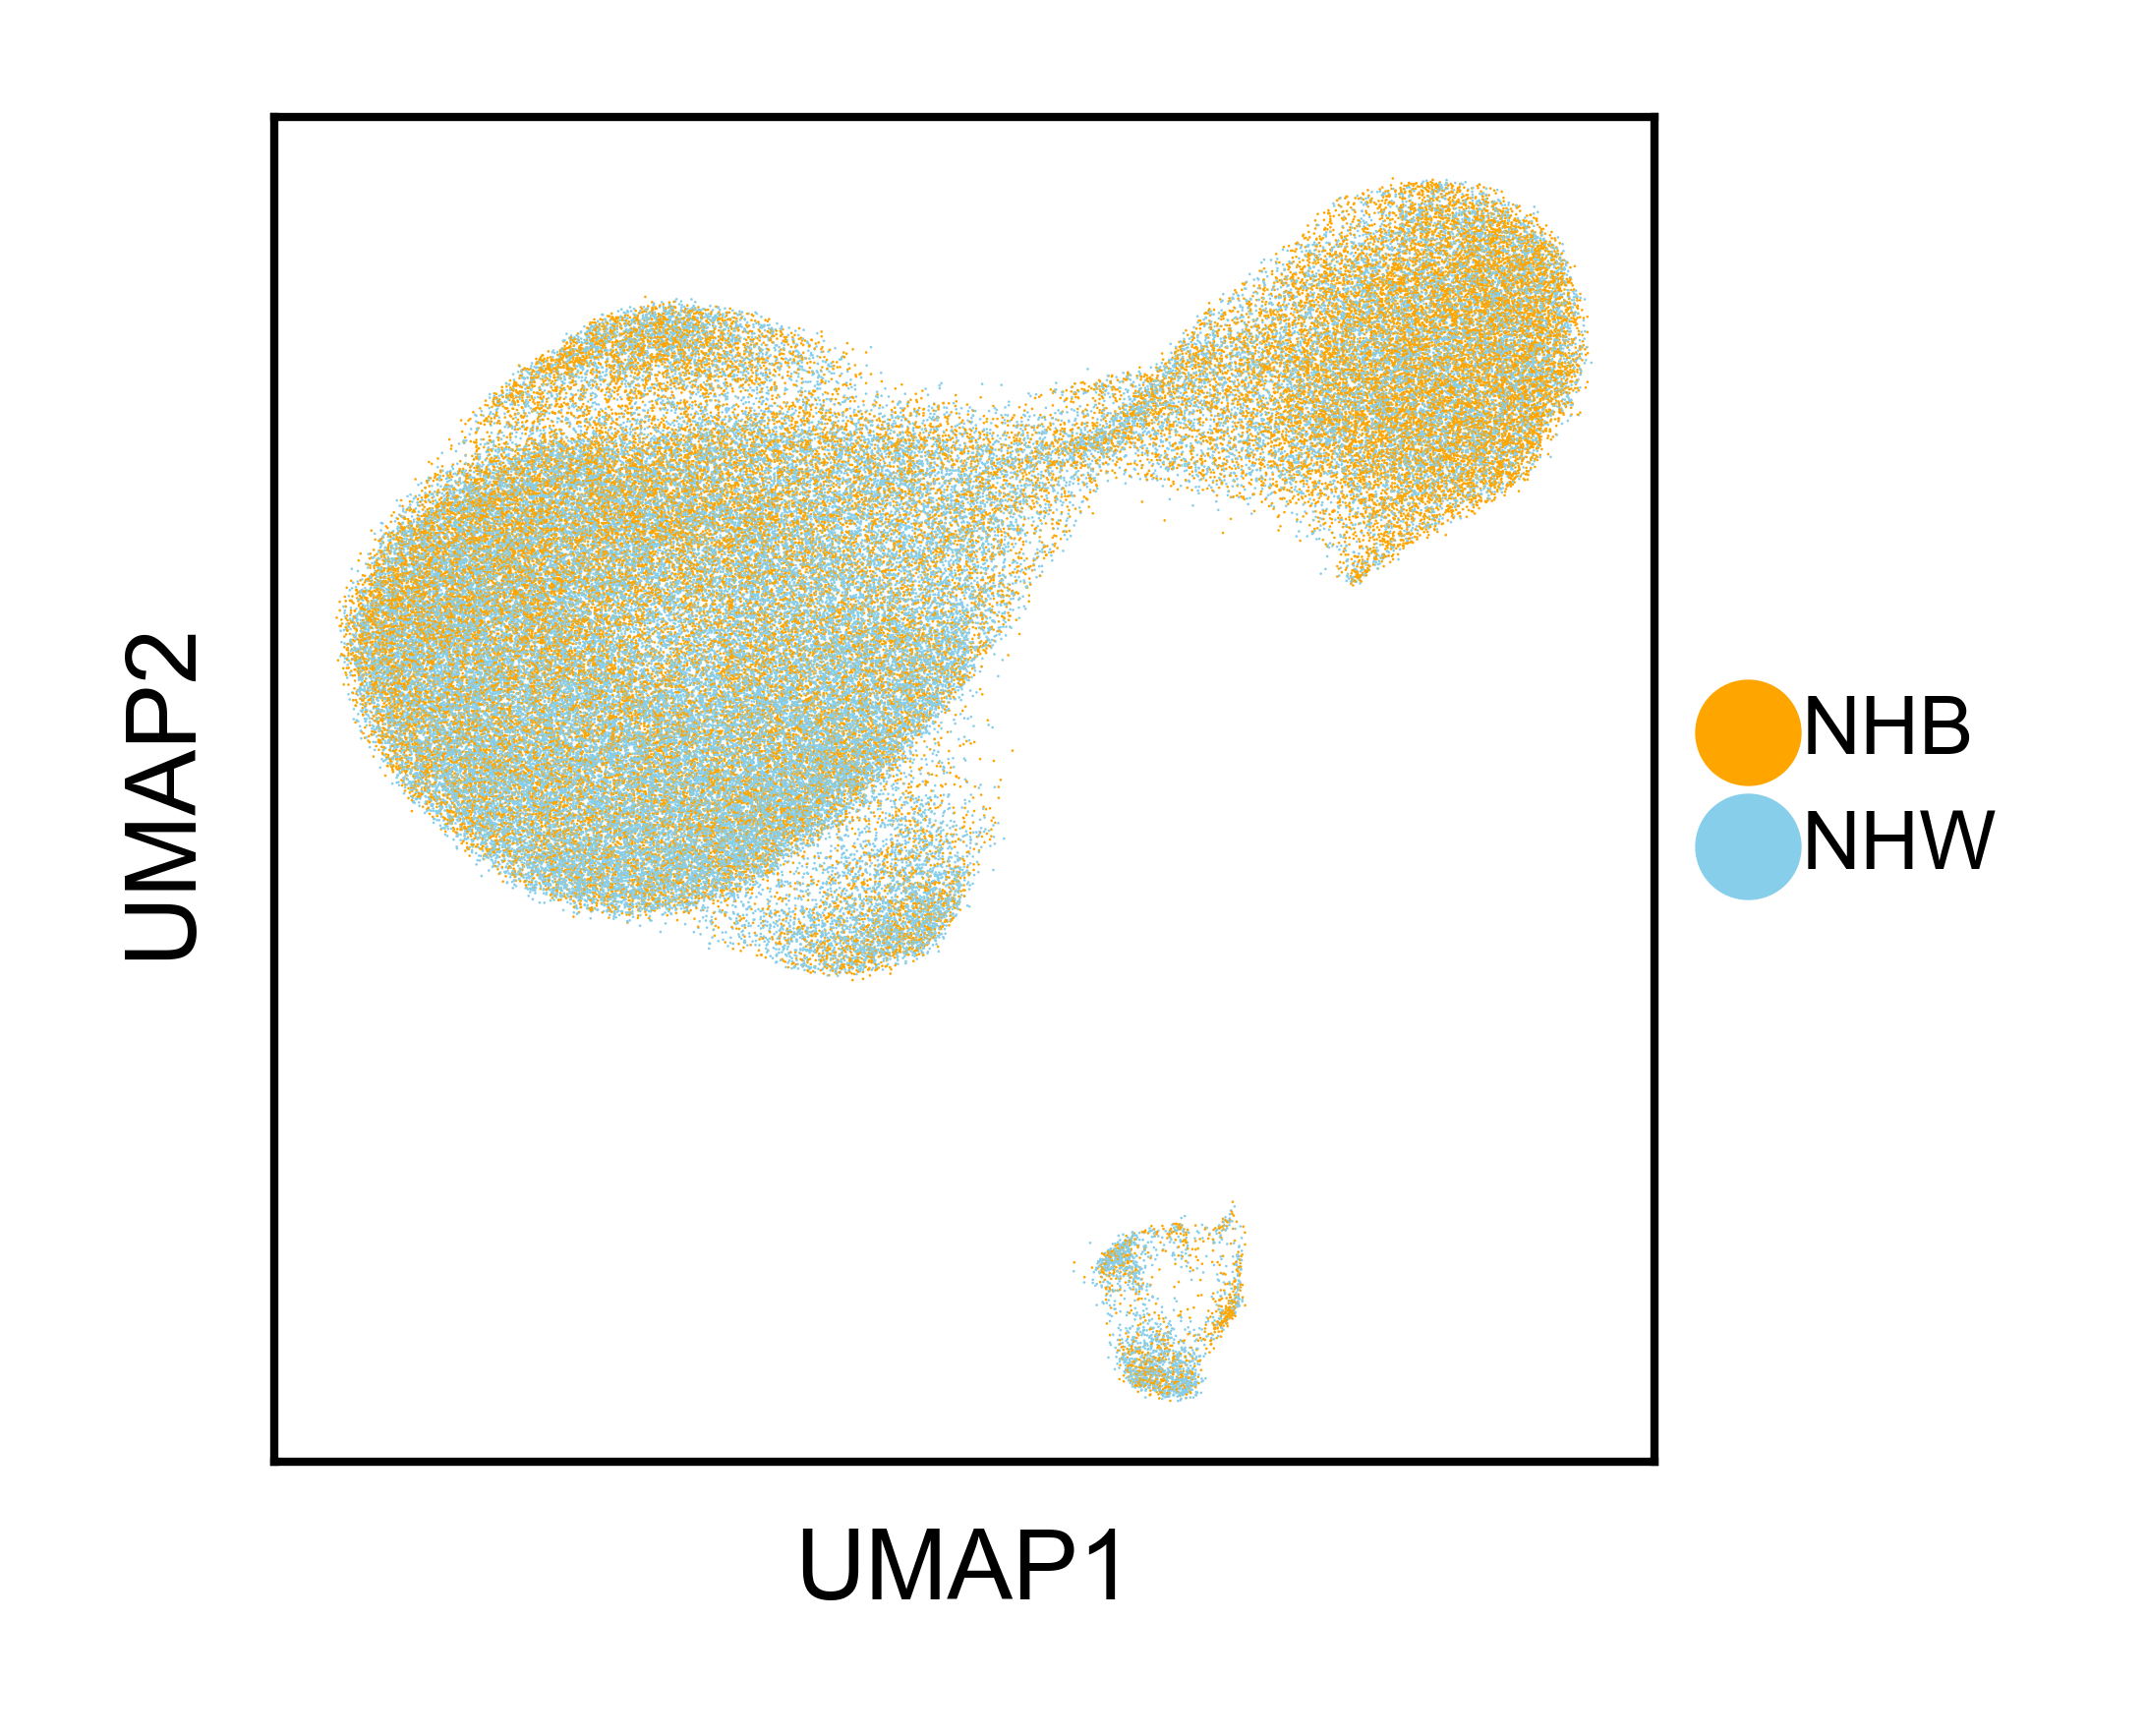

In [12]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race'
d.obs['race'] = [str(x).replace('1','NHB').replace('0','NHW') for x in d.obs['race']]


order = cells_group['Mono']
pal_ordered = [palette_all[c] for c in order]

sc.pl.umap(
    d,
    color=covar,
    palette=['orange','skyblue'],
    size=.1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6/Mono_race.svg')

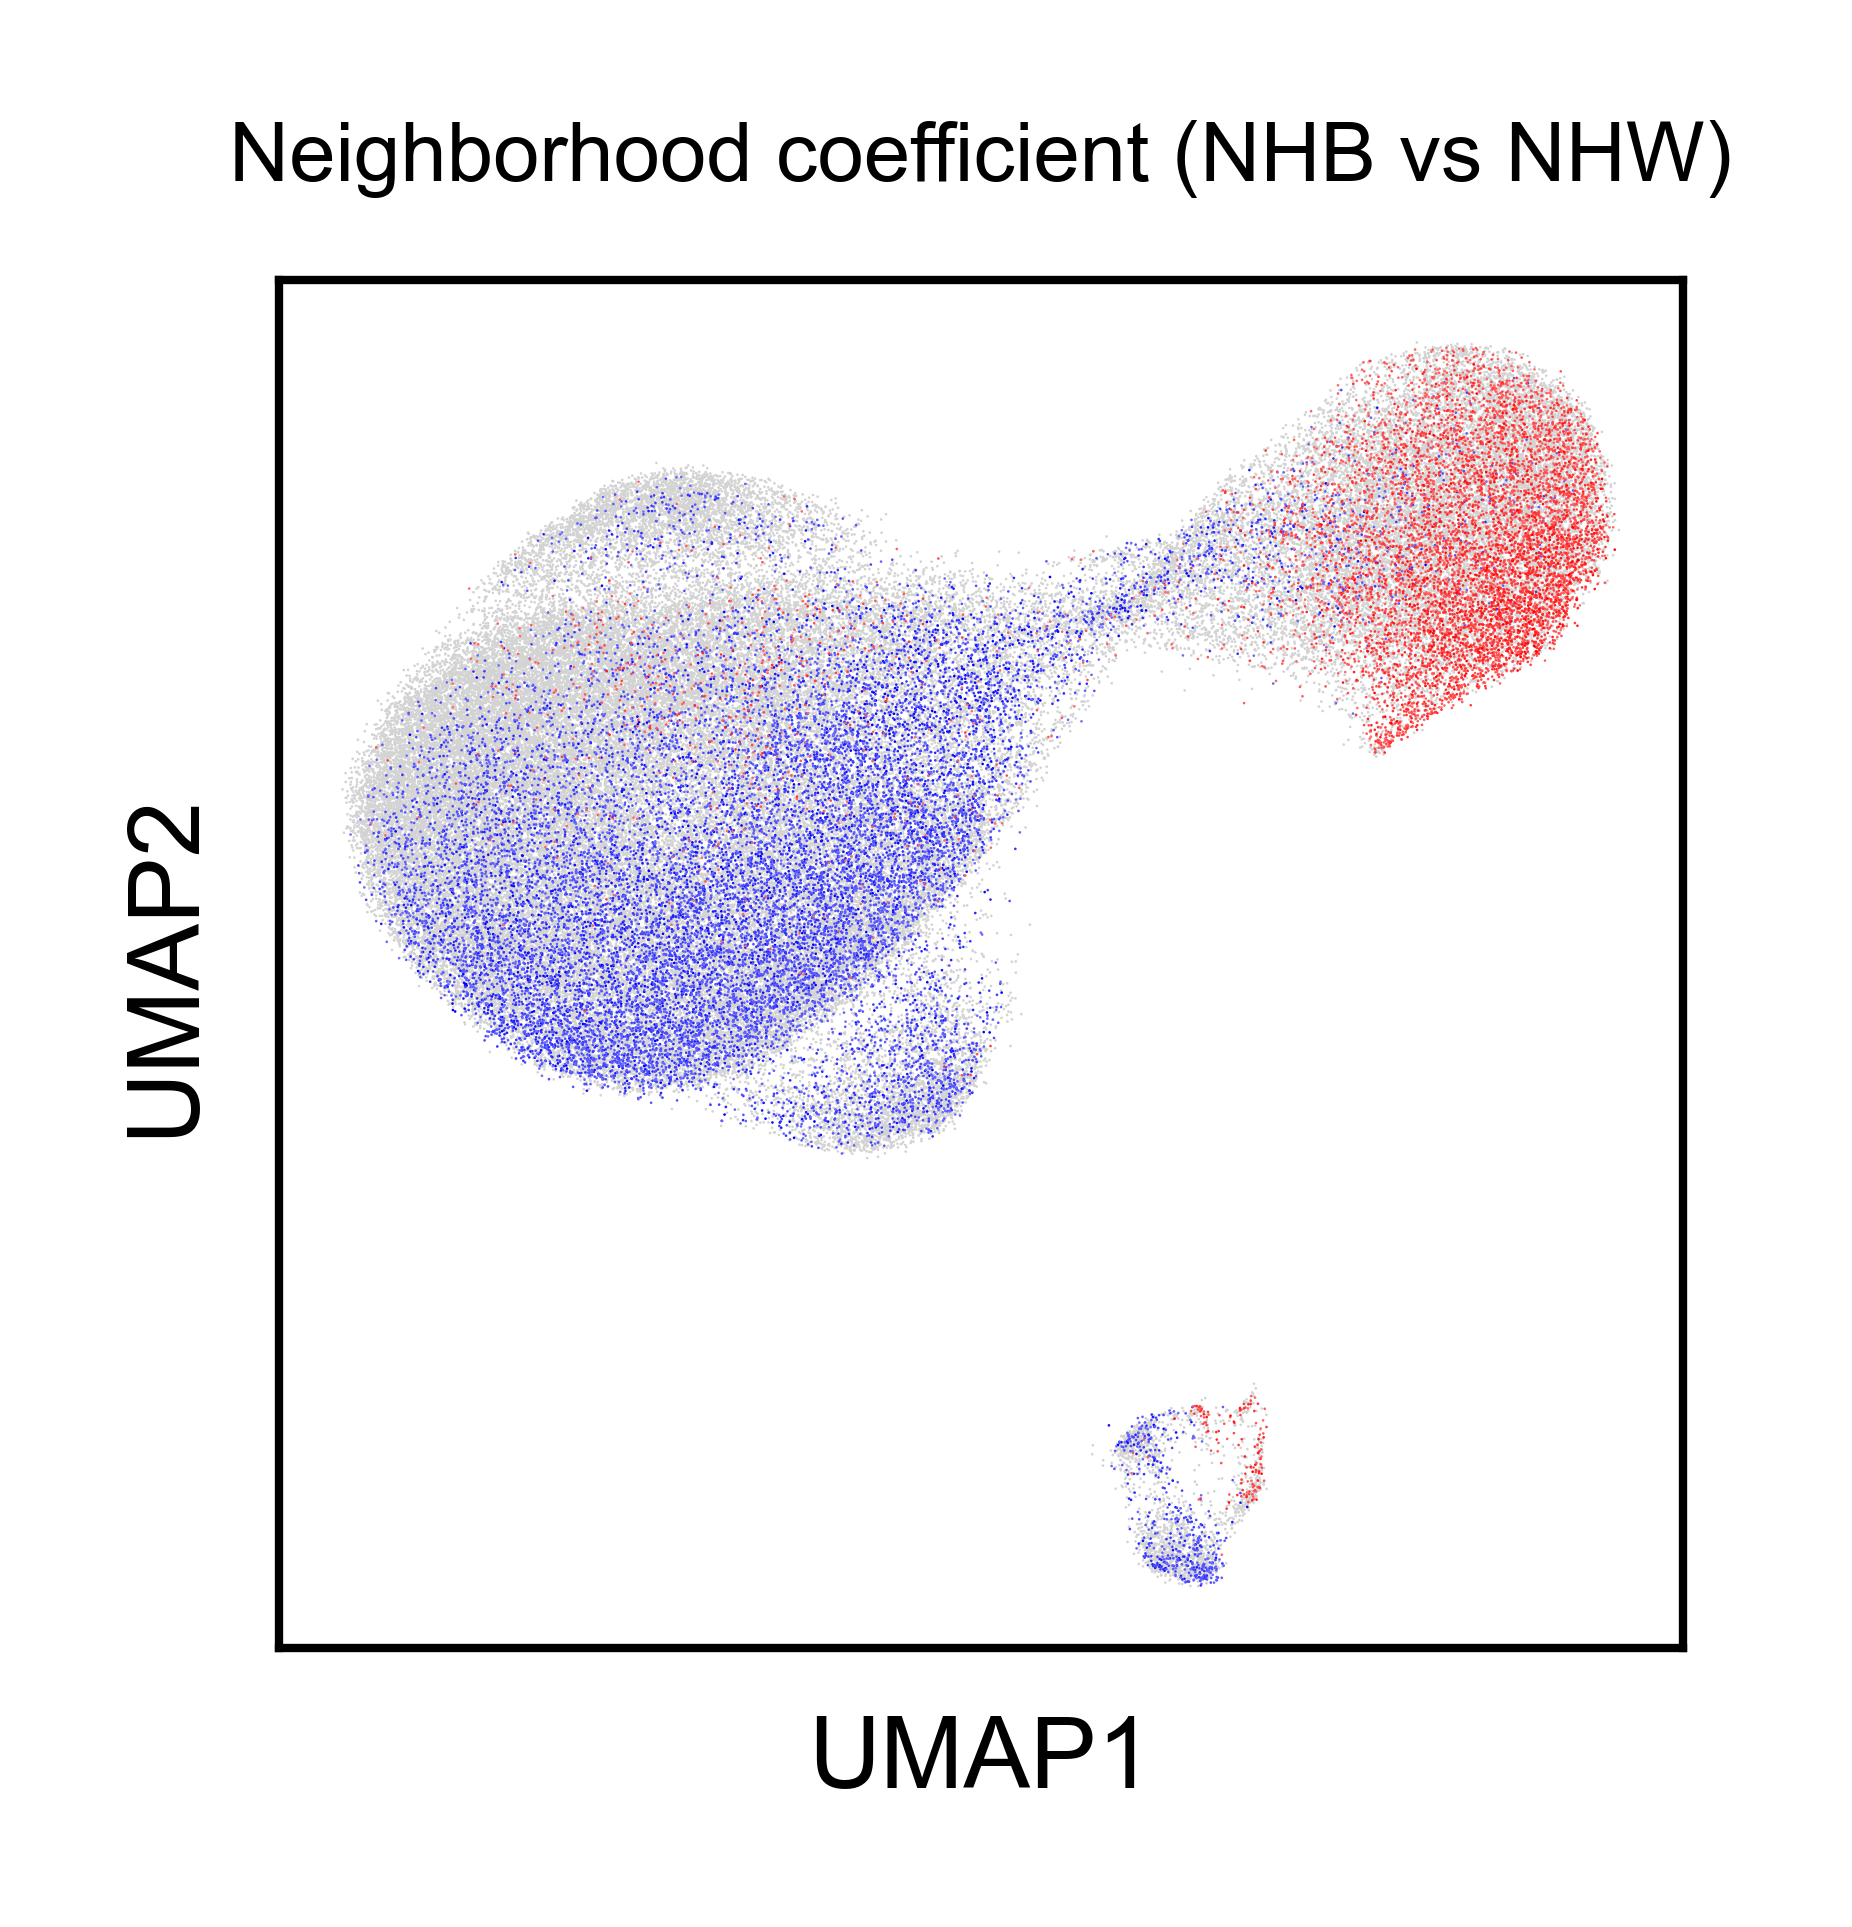

In [10]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race' 

coef_col = f"{covar}_coef"
fdr_col = f"{covar}_coef_fdr"
color_col = f"{covar}_coef_plot"

d.obs[color_col] = np.where(d.obs[fdr_col] < 0.1, d.obs[coef_col], np.nan)   # nan will show as gray in sc.pl.umap
sc.pl.umap(
    d,
    color=color_col,
    s=.1,
    ax=ax,
    vmin=-1,
    vmax=1,
    cmap='seismic',
    na_color='lightgray',   # Gray for nan (non-significant)
    title='',
    colorbar_loc=None,
    show=False         # So you can further edit if needed
)

# cbar = ax.collections[0].colorbar
# ticks = [-1, -0.5, 0, 0.5, 1]
# cbar.set_ticks(ticks)
# cbar.set_ticklabels([str(t) for t in ticks])


ax.set_title('Neighborhood coefficient (NHB vs NHW)',fontsize=5)
plt.savefig('plots/F6/Mono_NbCoeff.svg')

In [14]:
covar = 'race'
fdr_col = f"{covar}_coef_fdr"
coef_col = f"{covar}_coef"

tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]>0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Nonclassical Monocyte: 6533 (88.30%)
Classical Monocyte: 552 (7.46%)
Intermediate Monocyte: 309 (4.18%)
Cytotoxic Monocyte: 5 (0.07%)


In [15]:
order = cells_group['Mono']
pal_ordered = [palette_all[c] for c in order]

In [13]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]<0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Classical Monocyte: 14035 (87.42%)
Cytotoxic Monocyte: 423 (2.63%)
Intermediate Monocyte: 1231 (7.67%)
Nonclassical Monocyte: 365 (2.27%)


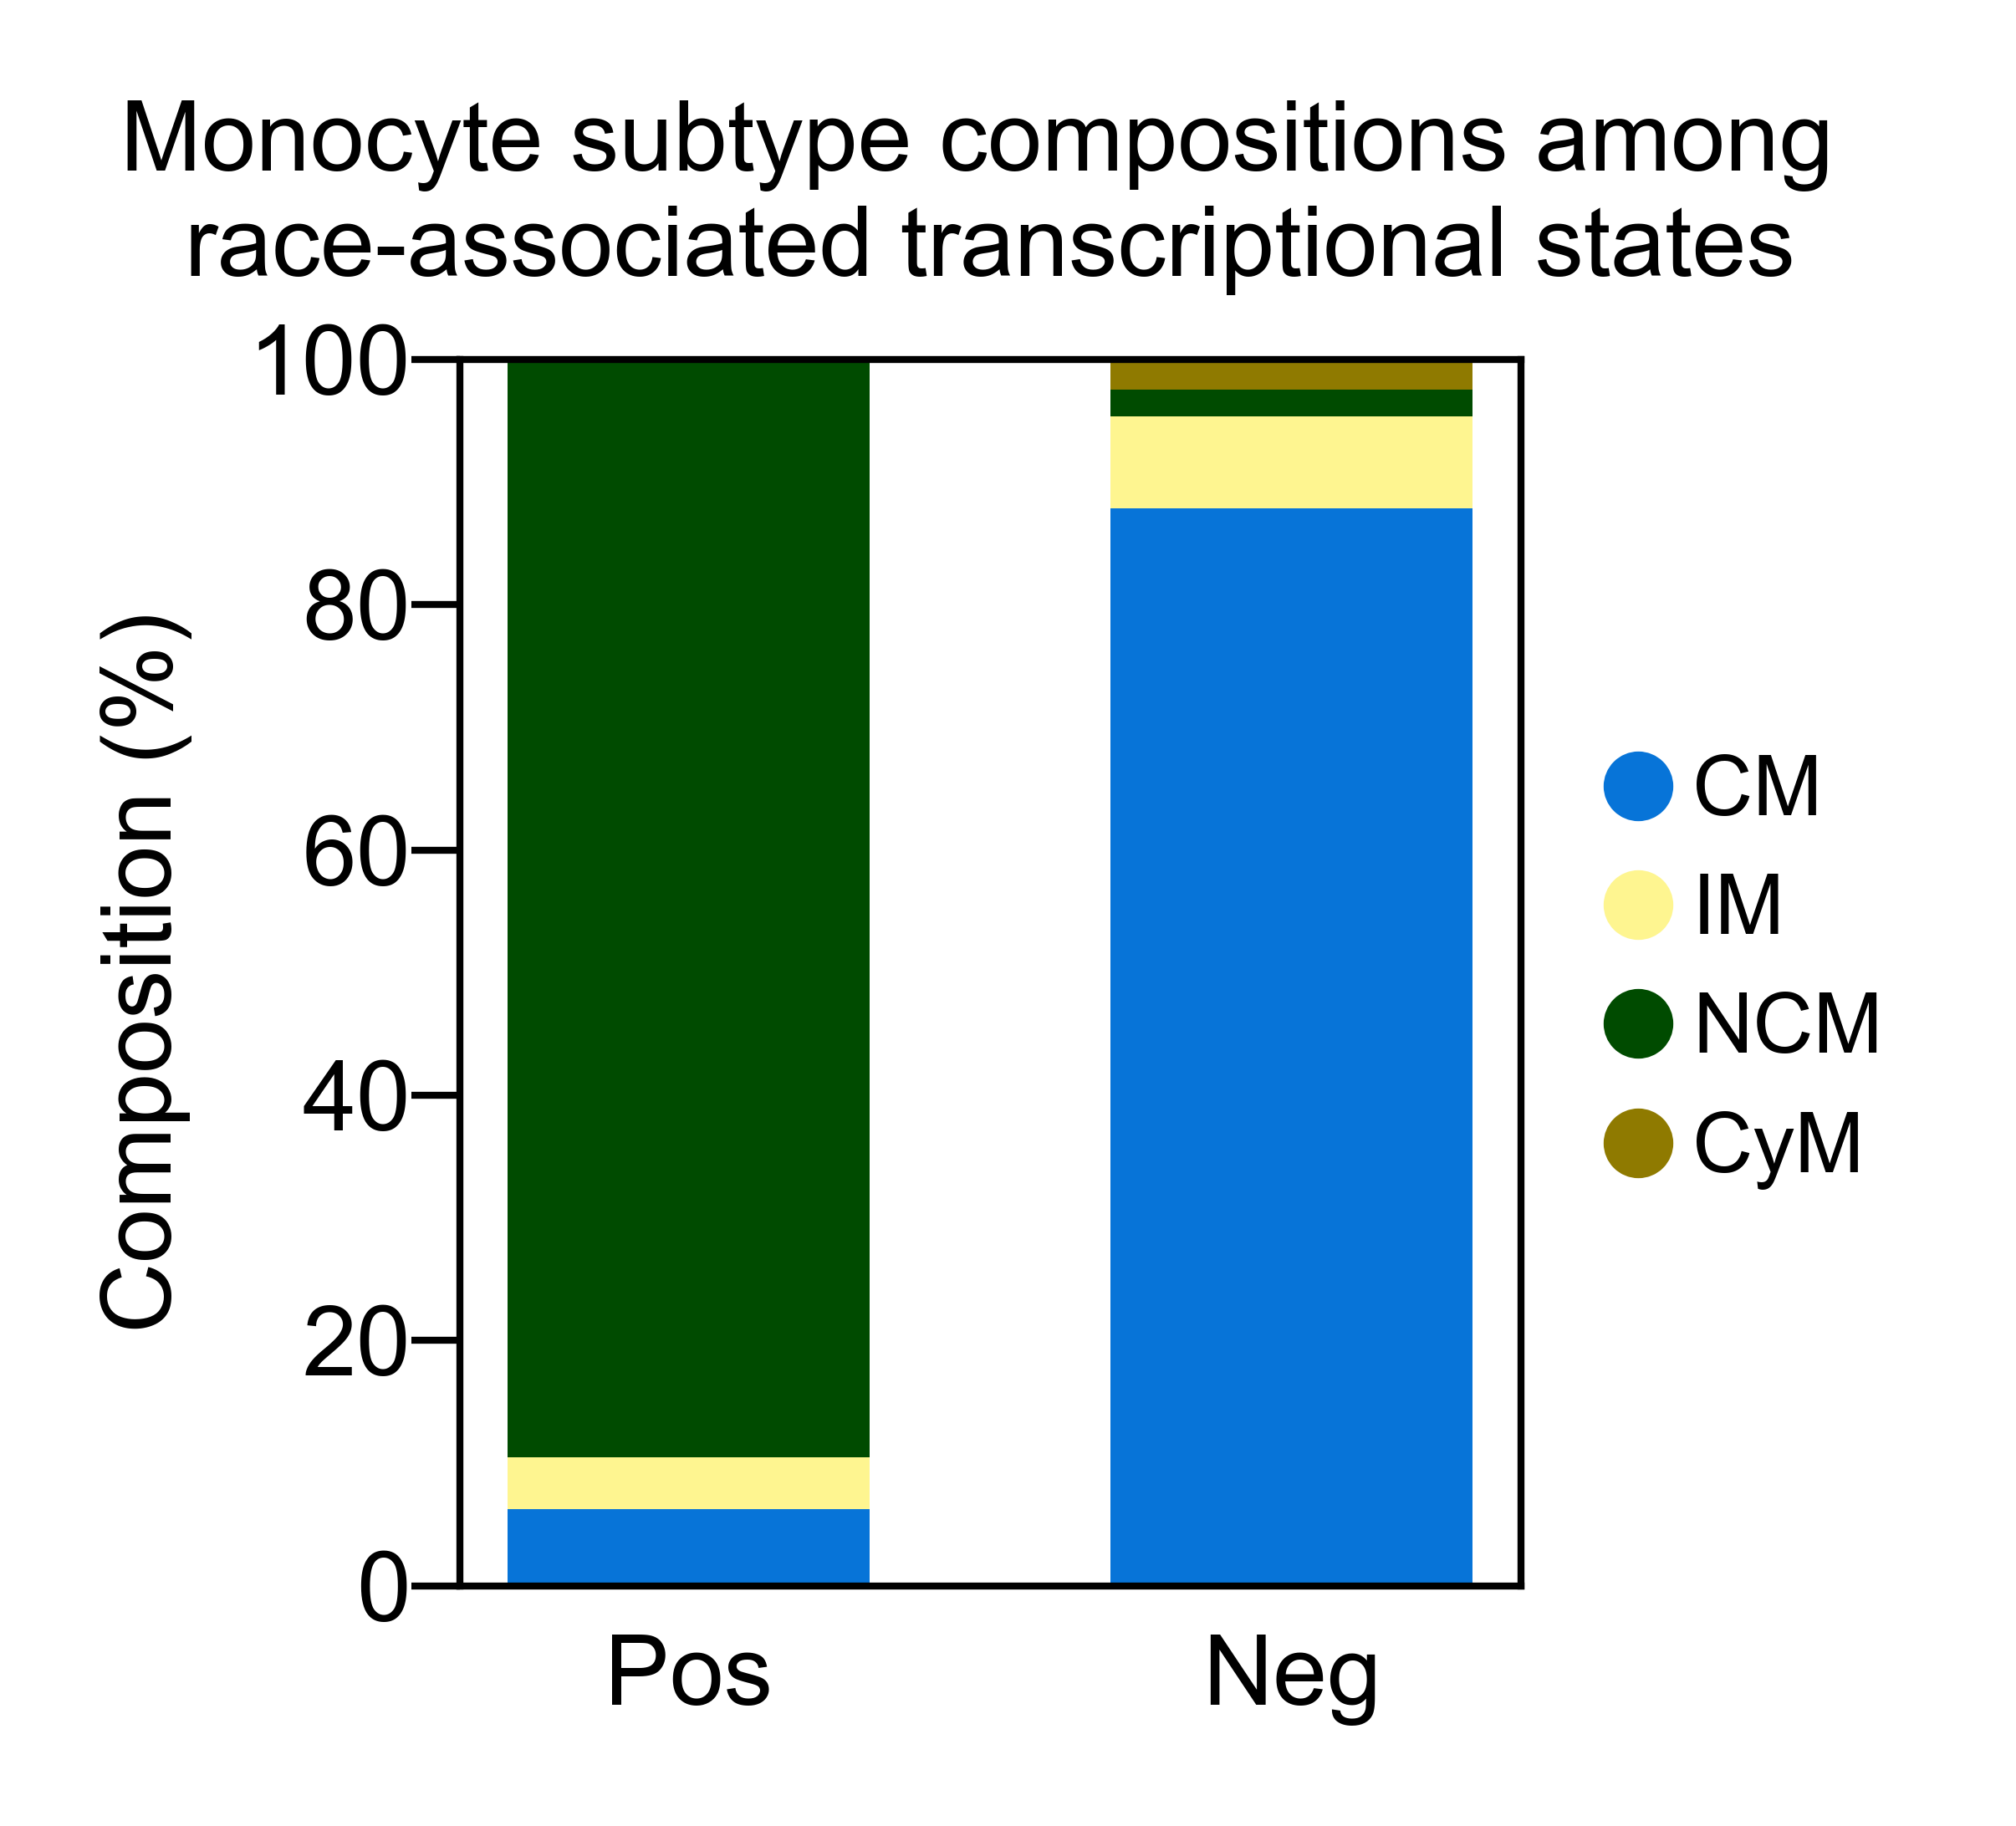

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

covar = "race"
fdr_col = f"{covar}_coef_fdr"
coef_col = f"{covar}_coef"

# positive-associated cells
tmp_pos = d[(d.obs[fdr_col] < 0.1) & (d.obs[coef_col] > 0)]
cnt_pos = Counter(tmp_pos.obs["celltype_level3"])

# negative-associated cells
tmp_neg = d[(d.obs[fdr_col] < 0.1) & (d.obs[coef_col] < 0)]
cnt_neg = Counter(tmp_neg.obs["celltype_level3"])

# all cell types appearing in either group
celltypes = sorted(set(cnt_pos.keys()) | set(cnt_neg.keys()))

# count table
df_counts = pd.DataFrame({
    "cell_type": celltypes,
    "pos_count": [cnt_pos.get(ct, 0) for ct in celltypes],
    "neg_count": [cnt_neg.get(ct, 0) for ct in celltypes],
})

# optional: keep only cell types present in your palette/order
celltype_order = [ct for ct in palette_all.keys() if ct in df_counts["cell_type"].values]
df_counts["cell_type"] = pd.Categorical(df_counts["cell_type"], categories=celltype_order, ordered=True)
df_counts = df_counts.sort_values("cell_type").reset_index(drop=True)

# calculate percentages within pos and neg separately
df_counts["pos_pct"] = df_counts["pos_count"] / df_counts["pos_count"].sum() * 100
df_counts["neg_pct"] = df_counts["neg_count"] / df_counts["neg_count"].sum() * 100

# reshape for plotting
dat = (
    df_counts
    .set_index("cell_type")[["pos_pct", "neg_pct"]]
    .T
)
dat.index = ["Pos", "Neg"]

# colors in desired order
pal_ordered = [palette_all[ct] for ct in dat.columns]

# plot
fig, ax = plt.subplots(figsize=(2,1.8))

bottom = pd.Series(0, index=dat.index)

for ct, color in zip(dat.columns, pal_ordered):
    ax.bar(
        dat.index,
        dat[ct],
        bottom=bottom,
        color=color,
        label=ct,
        width=0.6
    )
    bottom += dat[ct]

ax.set_ylabel("Composition (%)", fontsize=7)
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", labelsize=7)
ax.set_title('Monocyte subtype compositions among \nrace-associated transcriptional states')


# plot legend
from matplotlib.lines import Line2D

label_map = {
    "Classical Monocyte": "CM",
    "Cytotoxic Monocyte": "CyM",
    "Intermediate Monocyte": "IM",
    "Nonclassical Monocyte": "NCM"
}

handles = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor=palette_all[ct],
        markeredgecolor=palette_all[ct],
        markersize=4,
        label=label_map.get(ct, ct)
    )
    for ct in dat.columns
]

ax.legend(
    handles=handles,
    title="",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=6,
    handletextpad=0.4
)

plt.tight_layout()
plt.savefig("plots/S4/Mono_asso_composition.pdf", bbox_inches="tight")
plt.show()

In [23]:
df_counts

,cell_type,pos_count,neg_count,pos_pct,neg_pct
0,Classical Monocyte,552,14035,7.460468,87.423695
1,Intermediate Monocyte,309,1231,4.176240,7.667871
2,Nonclassical Monocyte,6533,365,88.295716,2.273577
3,Cytotoxic Monocyte,5,423,0.067577,2.634857


## Disease state

In [11]:
cts = 0

for group in ['HRL','DCIS','BC']:

    for db in ['immport']:

        cts += 1
        
        raw = pd.read_csv(
            f'data/Figure6/CNArankNHBvsW_Mono_{group}_{db}.csv', 
            index_col=0)
        
        dfp = raw#[raw['FDR q-val']<0.05].sort_values('NES', ascending=False)

        dfp['Tag %'] = (
            dfp['Tag %']
            .astype(str)
            .apply(lambda x: eval(x) if '/' in x else float(x))
        )
        dfp['Tag %'] = dfp['Tag %'] * 100
        dfp['log_p'] = -np.log10(dfp['FDR q-val'].replace(0, 1e-300))
        
        # Sort by NES
        dfp = dfp.sort_values('NES', ascending=False)
        
        # filter - 
        # dfp = dfp[dfp['Tag %']>=30]
        dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]


        dfp['analysis_group'] = [group]*dfp.shape[0]
        dfp['analysis_db'] = [db]*dfp.shape[0]

        out = dfp if cts==1 else pd.concat([out, dfp])


out        

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_group,analysis_db
5,prerank,T CELL PROLIFERATION,0.658654,1.661725,0.000000,0.051969,0.047,36.486486,8.70%,PTPRC;SPN;PIK3CG;LILRB1;PTPN6;DOCK2;MSN;DOCK8;...,1.284254,HRL,immport
7,prerank,ANTIVIRAL INNATE IMMUNE RESPONSE,0.690128,1.639059,0.005222,0.046136,0.085,48.979592,14.37%,OAS1;TNF;DUS2;IFIT2;IFIT3;NLRP6;ZDHHC1;MX1;TBK...,1.335961,HRL,immport
8,prerank,LYMPHOCYTE PROLIFERATION,0.620060,1.631787,0.000000,0.036767,0.098,33.333333,8.70%,PTPRC;SPN;ADA;PIK3CG;LILRB1;PTPN6;NFKBIZ;DOCK2...,1.434538,HRL,immport
10,prerank,INTERFERON ALPHA/BETA SIGNALING,0.669034,1.630316,0.000000,0.028106,0.099,57.142857,9.61%,IFITM3;IFITM1;IFITM2;HLA-E;OAS1;PTPN6;OAS3;JAK...,1.551204,HRL,immport
11,prerank,FC RECEPTOR MEDIATED STIMULATORY SIGNALING PAT...,0.776118,1.629417,0.001361,0.022485,0.099,36.363636,5.94%,LYN;HCK;FCER1G;MYO1G;FGR;VAV1;PRKCE;FYN,1.648114,HRL,immport
...,...,...,...,...,...,...,...,...,...,...,...,...,...
38,prerank,"COMPLEMENT ACTIVATION, LECTIN PATHWAY",-0.826907,-1.477298,0.072816,0.145651,0.727,16.666667,0.61%,FCN1,0.836688,BC,immport
32,prerank,ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE,-0.656736,-1.524528,0.033419,0.125133,0.582,35.000000,11.29%,RPL39;FAU;IL6R;RNASE2;TREX1;OTUD7B;NOD2,0.902629,BC,immport
18,prerank,INNATE IMMUNE RESPONSE IN MUCOSA,-0.807011,-1.670081,0.010840,0.037802,0.197,16.666667,0.38%,RPL39;FAU,1.422488,BC,immport
15,prerank,ANTIMICROBIAL PEPTIDES,-0.662724,-1.676692,0.003030,0.052604,0.186,25.714286,6.32%,LYZ;S100A8;S100A9;RNASE6;CCR2;CD4;BPI;ELANE;ATOX1,1.278984,BC,immport


### HRL

In [12]:
DzState, db = 'HRL', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['T CELL PROLIFERATION', 'ANTIVIRAL INNATE IMMUNE RESPONSE',
       'LYMPHOCYTE PROLIFERATION', 'INTERFERON ALPHA/BETA SIGNALING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'NATURAL KILLER CELL ACTIVATION', 'RAP1 SIGNALLING',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       'T CELL COSTIMULATION', 'B CELL ACTIVATION',
       'LYMPHOCYTE COSTIMULATION',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'B CELL DIFFERENTIATION', 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',
       'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'COSTIMULATION BY THE CD28 FAMILY',
       'ANTIGEN RECEPTOR-MEDIATED 

In [13]:
paths_relevant = [
    # 'T CELL PROLIFERATION', 
    'ANTIVIRAL INNATE IMMUNE RESPONSE',
    # 'LYMPHOCYTE PROLIFERATION', 
    'INTERFERON ALPHA/BETA SIGNALING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       # 'NATURAL KILLER CELL ACTIVATION', 
    'RAP1 SIGNALLING',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       # 'T CELL COSTIMULATION', 
    # 'B CELL ACTIVATION',
       # 'LYMPHOCYTE COSTIMULATION',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
    #    'B CELL DIFFERENTIATION', 
    # 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'COSTIMULATION BY THE CD28 FAMILY',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE', 
    'DIAPEDESIS',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'LEUKOCYTE HOMEOSTASIS',
       'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
       'FLT3 SIGNALING', 
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'LEUKOCYTE MEDIATED IMMUNITY', 
    'INTERLEUKIN-2 FAMILY SIGNALING',
       # 'TOLERANCE INDUCTION', 
    'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       # 'HUMORAL IMMUNE RESPONSE MEDIATED BY CIRCULATING IMMUNOGLOBULIN',
       'MYELOID LEUKOCYTE MIGRATION', 
       'LEUKOCYTE CHEMOTAXIS',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
       # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'ANTIMICROBIAL PEPTIDES', 
    # 'INNATE IMMUNE RESPONSE IN MUCOSA',
       'ANTIMICROBIAL HUMORAL RESPONSE'
]

In [14]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_group,analysis_db
7,prerank,ANTIVIRAL INNATE IMMUNE RESPONSE,0.690128,1.639059,0.005222,0.046136,0.085,48.979592,14.37%,OAS1;TNF;DUS2;IFIT2;IFIT3;NLRP6;ZDHHC1;MX1;TBK...,1.335961,HRL,immport
10,prerank,INTERFERON ALPHA/BETA SIGNALING,0.669034,1.630316,0.000000,0.028106,0.099,57.142857,9.61%,IFITM3;IFITM1;IFITM2;HLA-E;OAS1;PTPN6;OAS3;JAK...,1.551204,HRL,immport
11,prerank,FC RECEPTOR MEDIATED STIMULATORY SIGNALING PAT...,0.776118,1.629417,0.001361,0.022485,0.099,36.363636,5.94%,LYN;HCK;FCER1G;MYO1G;FGR;VAV1;PRKCE;FYN,1.648114,HRL,immport
13,prerank,RAP1 SIGNALLING,0.814437,1.585849,0.014706,0.040303,0.213,46.666667,12.16%,RAP1B;RAP1GAP2;RASGRP2;YWHAZ;PRKACB;PRKACA;RAF1,1.394666,HRL,immport
14,prerank,FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS,0.614211,1.580750,0.001202,0.039109,0.230,34.117647,8.22%,LYN;FCGR3A;CYFIP2;HCK;PLD4;ACTR3;FGR;WASF2;VAV...,1.407718,HRL,immport
18,prerank,FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED I...,0.763442,1.567819,0.006925,0.030186,0.281,35.000000,5.94%,LYN;HCK;MYO1G;FGR;VAV1;PRKCE;FYN,1.520192,HRL,immport
19,prerank,IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPT...,0.763442,1.567819,0.006925,0.030186,0.281,35.000000,5.94%,LYN;HCK;MYO1G;FGR;VAV1;PRKCE;FYN,1.520192,HRL,immport
23,prerank,"COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY",0.800362,1.519253,0.013177,0.051571,0.480,16.666667,1.58%,CFD;C3,1.287590,HRL,immport
27,prerank,"INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING",0.632266,1.499348,0.017173,0.058054,0.593,43.750000,12.10%,LYN;HCK;PTPN6;JAK1;CBL;VAV1;RAPGEF1;YWHAZ;IL3R...,1.236170,HRL,immport
32,prerank,ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY,0.542462,1.469494,0.002240,0.072506,0.723,27.922078,9.85%,LYN;PTPRC;CD79B;ADA;PTPN6;NFKBIZ;PTPRJ;LCP2;CS...,1.139625,HRL,immport


In [15]:
dfp_sel.to_csv(f'data/Tables/Mono_{DzState}.csv')

In [20]:
short_name_map = {
    'ANTIVIRAL INNATE IMMUNE RESPONSE':
        'ANTIVIRAL INNATE IMMUNE RESP',

    'INTERFERON ALPHA/BETA SIGNALING':
        'IFN-ALPHA/BETA SIG',

    'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY':
        'FC R-MEDIATED STIM SIG',

    'RAP1 SIGNALLING':
        'RAP1 SIGNALING',

    'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS':
        'FCGR-DEP PHAGOCYTOSIS',

    'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        'IMMUNE REG CELL SURF R SIG IN PHAGOCYT',

    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        'FC-GAMMA R SIG IN PHAGOCYTOSIS',

    'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY':
        'COMPLEMENT ACTIV, ALT PATHWAY',

    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING':
        'IL-3, IL-5, GM-CSF SIG',

    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        'AG R-MEDIATED SIG PATHWAY',

    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'LEUKO ACTIV IN IMMUNE RESP',

    'DIAPEDESIS':
        'DIAPEDESIS',

    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'CELL ACTIV IN IMMUNE RESP',

    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        'NEG REG OF LEUKO ACTIV',

    'LEUKOCYTE HOMEOSTASIS':
        'LEUKO HOMEOSTASIS',

    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY':
        'NEG REG OF TLR4 SIG',

    'FLT3 SIGNALING':
        'FLT3 SIG',

    'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS':
        'CSF1/M-CSF SIG IN MYELOID CELLS',

    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        'NEG REG OF IMMUNE RESP',

    'LEUKOCYTE MEDIATED IMMUNITY':
        'LEUKO MEDIATED IMMUNITY',

    'INTERLEUKIN-2 FAMILY SIGNALING':
        'IL-2 FAMILY SIG',

    'ROS AND RNS PRODUCTION IN PHAGOCYTES':
        'ROS/RNS PROD IN PHAGOCYTES',

    'MYELOID LEUKOCYTE MIGRATION':
        'MYELOID LEUKO MIGRATION',

    'LEUKOCYTE CHEMOTAXIS':
        'LEUKO CHEMOTAXIS',

    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        'IL-4, IL-13 SIG',

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        'LEUKO MIGR IN INFLAMM RESP',

    'COMPLEMENT ACTIVATION, LECTIN PATHWAY':
        'COMPLEMENT ACTIV, LECTIN PATHWAY',

    'ANTIMICROBIAL PEPTIDES':
        'ANTIMICROBIAL PEPTIDES',

    'ANTIMICROBIAL HUMORAL RESPONSE':
        'ANTIMICROBIAL HUMORAL RESP'
}

In [21]:
triangle_map = {
    'ANTIVIRAL INNATE IMMUNE RESPONSE':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'INTERFERON ALPHA/BETA SIGNALING':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis / Fc receptor-mediated uptake

    'RAP1 SIGNALLING':
        {"marker": "^", "color": "#009E57"},  # green; Migration / chemotaxis

    'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis

    'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis

    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis

    'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY':
        {"marker": "^", "color": "#D7191C"},  # red; Complement

    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival

    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related

    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'DIAPEDESIS':
        {"marker": "^", "color": "#009E57"},  # green; Migration / chemotaxis

    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        {"marker": "^", "color": "#000000"},  # black; Immunoregulatory

    'LEUKOCYTE HOMEOSTASIS':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival

    'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY':
        {"marker": "^", "color": "#000000"},  # black; Immunoregulatory

    'FLT3 SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related / DC lineage signaling

    'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival

    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        {"marker": "^", "color": "#000000"},  # black; Immunoregulatory

    'LEUKOCYTE MEDIATED IMMUNITY':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'INTERLEUKIN-2 FAMILY SIGNALING':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'ROS AND RNS PRODUCTION IN PHAGOCYTES':
        {"marker": "v", "color": "#2CA9E1"},  # blue; Phagocytosis

    'MYELOID LEUKOCYTE MIGRATION':
        {"marker": "v", "color": "#009E57"},  # green; Migration / chemotaxis

    'LEUKOCYTE CHEMOTAXIS':
        {"marker": "v", "color": "#009E57"},  # green; Migration / chemotaxis

    'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING':
        {"marker": "v", "color": "#F46D1F"},  # orange; Antigen presentation related / type 2 immune interaction

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        {"marker": "v", "color": "#009E57"},  # green; Migration / chemotaxis

    'COMPLEMENT ACTIVATION, LECTIN PATHWAY':
        {"marker": "v", "color": "#D7191C"},  # red; Complement

    'ANTIMICROBIAL PEPTIDES':
        {"marker": "v", "color": "#7B4F2A"},  # brown; Antimicrobial response

    'ANTIMICROBIAL HUMORAL RESPONSE':
        {"marker": "v", "color": "#7B4F2A"}   # brown; Antimicrobial response
}

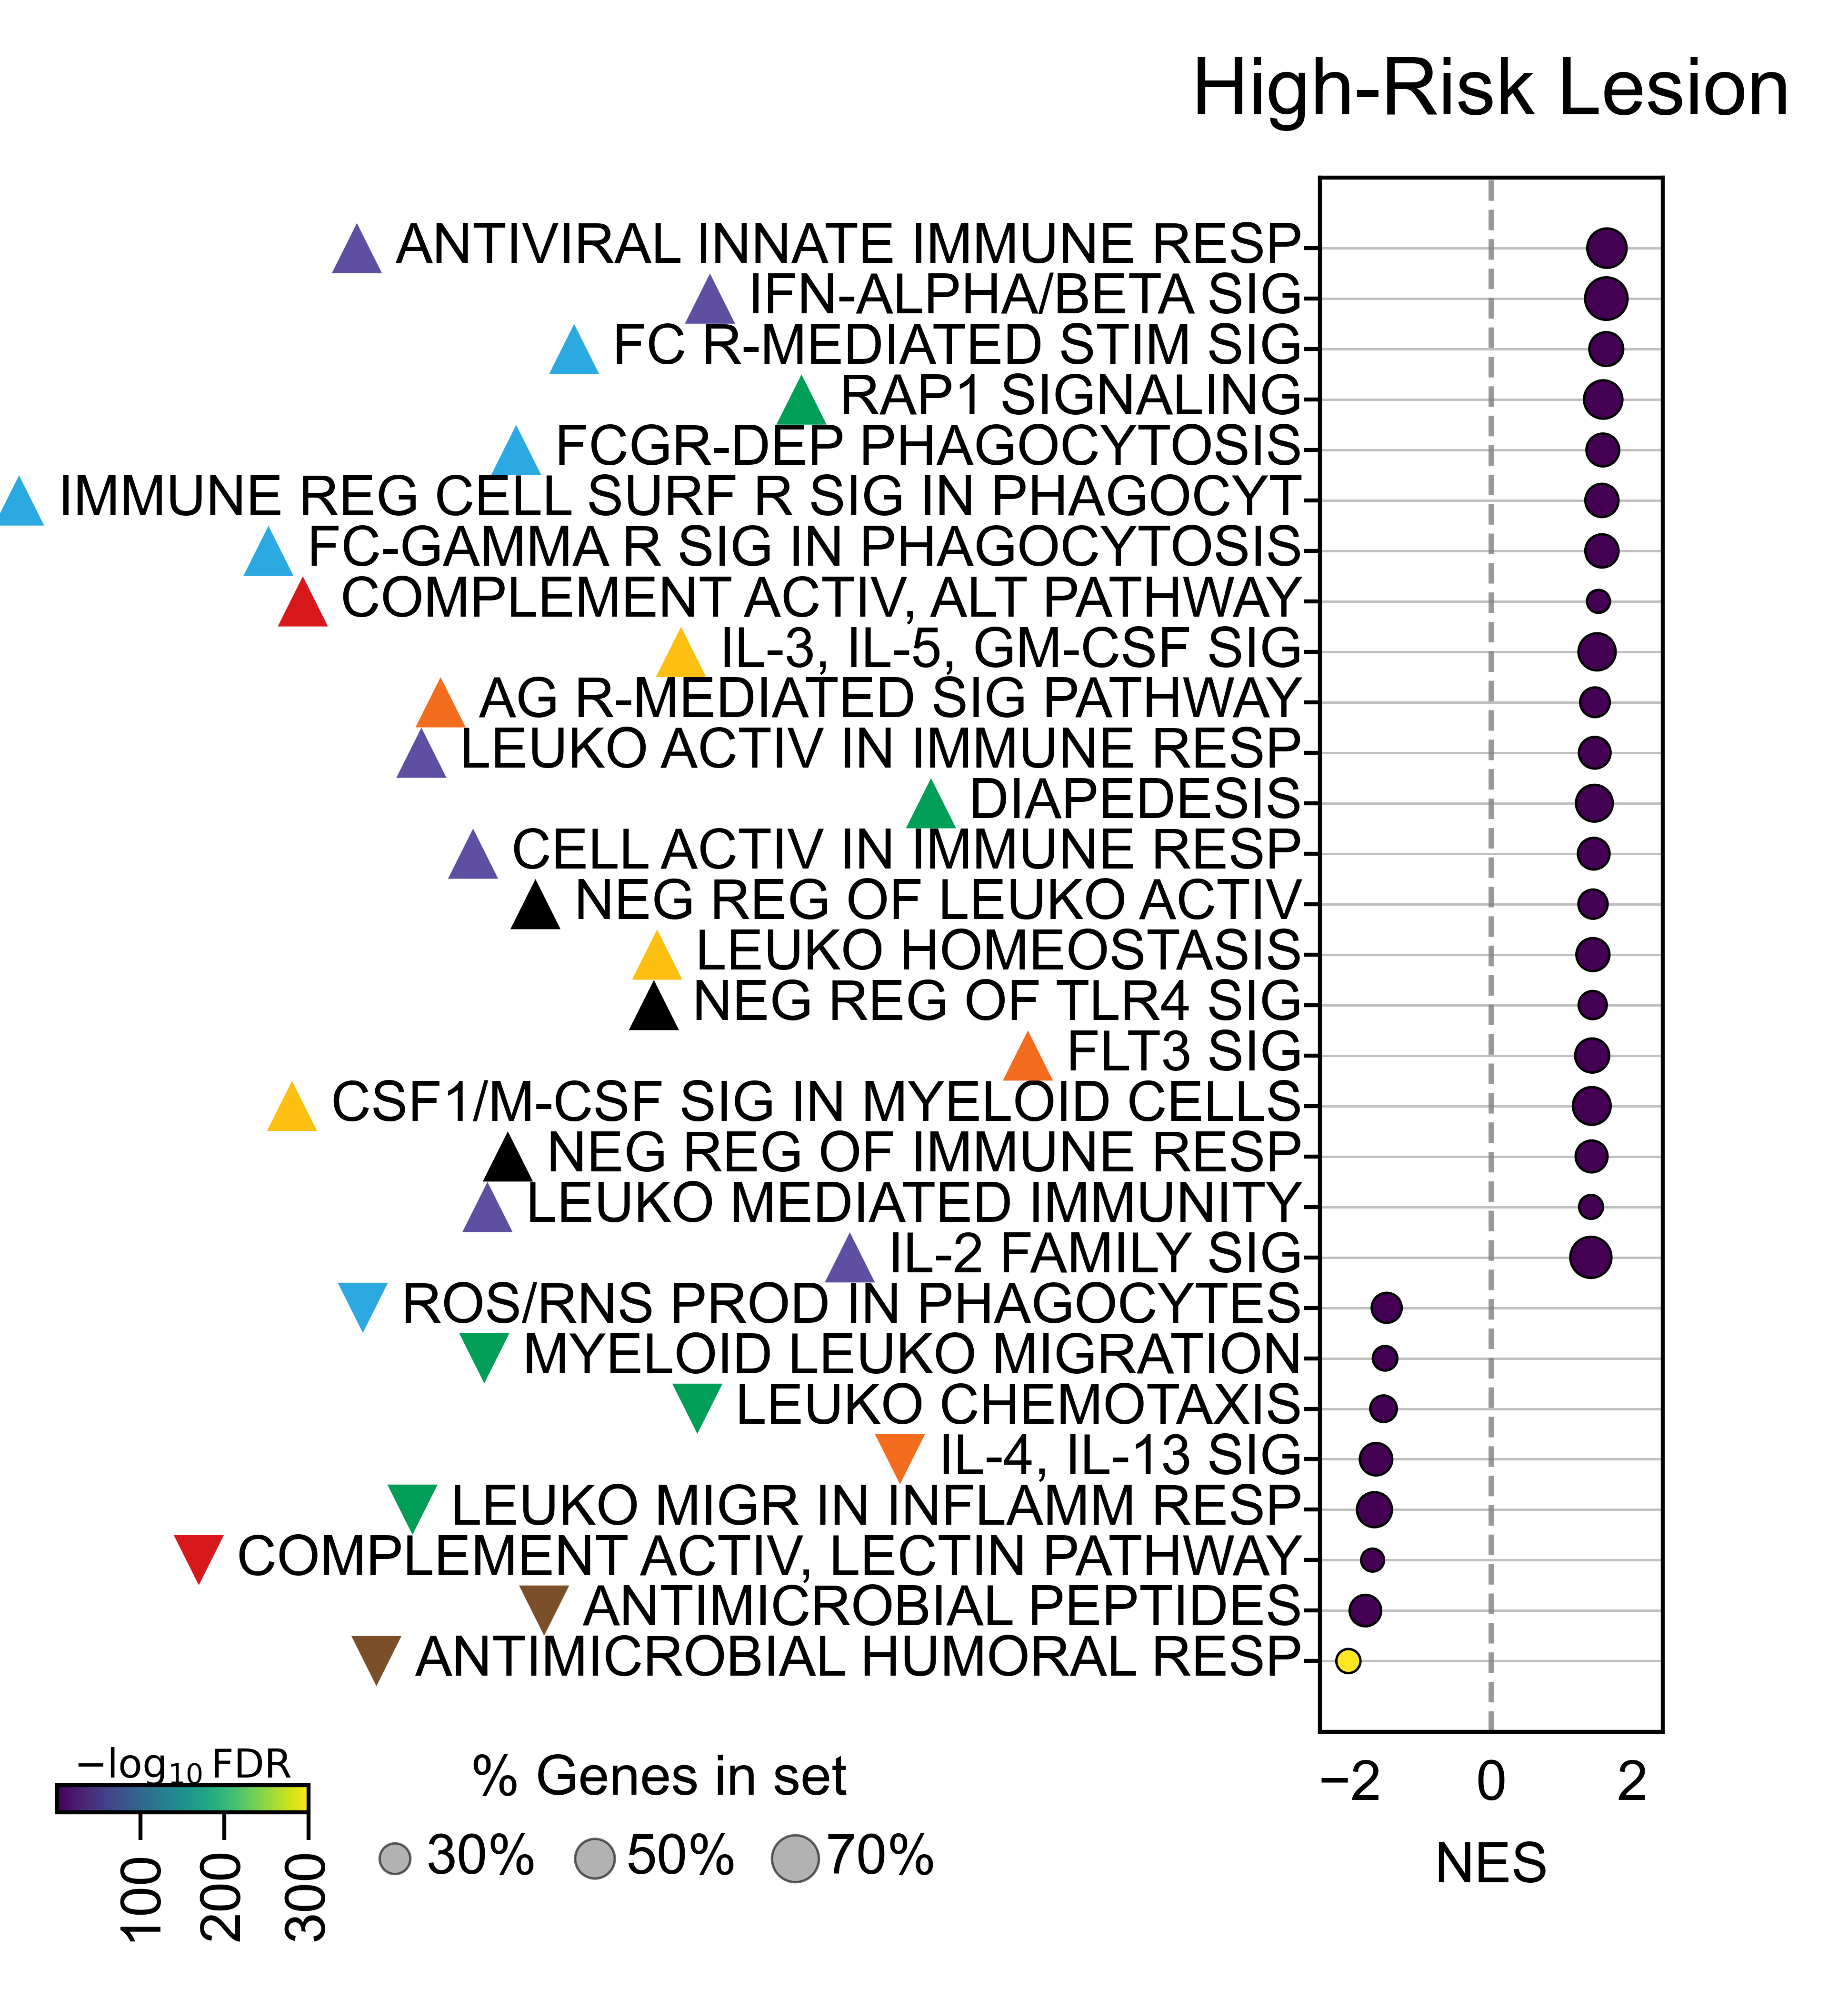

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 30
triangle_size = 40
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 4))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.68, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()

label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F5/Bubble_Mono_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### DCIS

In [16]:
DzState, db = 'DCIS', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS', 'FLT3 SIGNALING',
       'B CELL DIFFERENTIATION',
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       'NATURAL KILLER CELL ACTIVATION', 'B CELL ACTIVATION',
       'T CELL COSTIMULATION', 'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
       'RAP1 SIGNALLING', 'LYMPHOCYTE COSTIMULATION',
       'INTERLEUKIN-2 FAMILY SIGNALING',
       'COSTIMULATION BY THE CD28 FAMILY',
       'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       'LYMPHOCYTE PROLIFERATION',
       'NATURAL KILLER CELL MEDIATED IMMUNITY', 'DIAPEDESIS',
       'T CELL PROLIFERATION', 'GROWTH HORMONE RECEPTOR SIGNALING',
       'SIGNALING BY THE B CELL RECEPTOR (BCR)',
    

In [17]:
# prior version
# paths_relevant = [
#        'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
#        'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
#        'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
#        'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
#        'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS', 
#        'FLT3 SIGNALING',
#        # 'B CELL DIFFERENTIATION',
#        'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
#        # 'NATURAL KILLER CELL ACTIVATION', 
#     # 'B CELL ACTIVATION',
#     #    'T CELL COSTIMULATION', 
#     # 'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
#        'RAP1 SIGNALLING', 
#     # 'LYMPHOCYTE COSTIMULATION',
#        'INTERLEUKIN-2 FAMILY SIGNALING',
#        'COSTIMULATION BY THE CD28 FAMILY',
#        # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
#        # 'LYMPHOCYTE PROLIFERATION',
#        # 'NATURAL KILLER CELL MEDIATED IMMUNITY', 
#     'DIAPEDESIS',
#     #    'T CELL PROLIFERATION', 
#     # 'GROWTH HORMONE RECEPTOR SIGNALING',
#     #    'SIGNALING BY THE B CELL RECEPTOR (BCR)',
#        'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
#        # 'NATURAL KILLER CELL DIFFERENTIATION',
#        # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
#        # 'TOLERANCE INDUCTION', 
#     'MYELOID LEUKOCYTE MIGRATION',
#        'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
#        'LEUKOCYTE CHEMOTAXIS', 
#     'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
#        'ROS AND RNS PRODUCTION IN PHAGOCYTES',
#        # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
#        # 'INNATE IMMUNE RESPONSE IN MUCOSA',
#        'ANTIMICROBIAL HUMORAL RESPONSE', 
#     'ANTIMICROBIAL PEPTIDES'
# ]

In [18]:
paths_relevant = [
    'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',  # keep: monocytes are professional phagocytes; receptor-regulated phagocytosis is central
    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',  # keep: FcγR-mediated phagocytosis is highly relevant to monocytes
    'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',  # keep: monocytes express Fc receptors and respond to immune-complex stimulation
    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',  # keep: GM-CSF supports monocyte/macrophage activation and survival; IL-5 portion is less monocyte-specific
    'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',  # keep: canonical monocyte/macrophage phagocytic pathway
    # 'FLT3 SIGNALING',  # exclude/conditional: more DC progenitor/DC lineage biology than mature peripheral blood monocyte function
    # 'B CELL DIFFERENTIATION',  # exclude: B-cell lineage pathway, not monocyte-intrinsic
    'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',  # keep: CSF1/M-CSF is central to monocyte/macrophage survival and differentiation
    # 'NATURAL KILLER CELL ACTIVATION',  # exclude: NK-cell pathway, not monocyte-intrinsic
    # 'B CELL ACTIVATION',  # exclude: B-cell pathway, not monocyte-intrinsic
    # 'T CELL COSTIMULATION',  # exclude: primarily T-cell activation/costimulation, not monocyte-intrinsic
    'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',  # keep/conditional: monocytes can participate through Fc receptors, though this term often reflects NK-cell biology
    'RAP1 SIGNALLING',  # keep: Rap1 regulates integrin activation, adhesion, and migration in leukocytes including monocytes
    # 'LYMPHOCYTE COSTIMULATION',  # exclude: lymphocyte-focused, not monocyte-intrinsic
    # 'INTERLEUKIN-2 FAMILY SIGNALING',  # exclude/weak: mostly T/NK-cell cytokine biology rather than monocyte function
    # 'COSTIMULATION BY THE CD28 FAMILY',  # exclude: CD28-family costimulation is mainly T-cell/APC interaction, not monocyte-intrinsic
    # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',  # exclude: NK-cell cytotoxicity pathway
    # 'LYMPHOCYTE PROLIFERATION',  # exclude: lymphocyte-specific process
    # 'NATURAL KILLER CELL MEDIATED IMMUNITY',  # exclude: NK-cell pathway
    'DIAPEDESIS',  # keep: monocyte transendothelial migration is central to inflammatory trafficking
    # 'T CELL PROLIFERATION',  # exclude: T-cell-specific process
    # 'GROWTH HORMONE RECEPTOR SIGNALING',  # exclude/weak: not a canonical peripheral blood monocyte immune pathway
    # 'SIGNALING BY THE B CELL RECEPTOR (BCR)',  # exclude: B-cell receptor pathway
    # 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',  # exclude: usually TCR/BCR-driven lymphocyte signaling, not monocyte-intrinsic
    # 'NATURAL KILLER CELL DIFFERENTIATION',  # exclude: NK-cell lineage pathway
    # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',  # exclude: lymphocyte-focused pathway
    # 'TOLERANCE INDUCTION',  # exclude/conditional: monocytes can be immunoregulatory, but the pathway is broad and often APC/T-cell tolerance context
    'MYELOID LEUKOCYTE MIGRATION',  # keep: directly relevant to monocyte trafficking
    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',  # keep: monocyte recruitment/migration during inflammation
    'LEUKOCYTE CHEMOTAXIS',  # keep: monocyte chemotaxis is a core peripheral blood monocyte function
    'COMPLEMENT ACTIVATION, LECTIN PATHWAY',  # keep: complement-opsonization/inflammatory pathways are relevant to monocyte phagocytic responses
    'ROS AND RNS PRODUCTION IN PHAGOCYTES',  # keep: monocytes can generate oxidative/nitrosative antimicrobial mediators
    # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',  # exclude: tissue-context pathway, less clean for peripheral blood monocytes
    # 'INNATE IMMUNE RESPONSE IN MUCOSA',  # exclude: mucosal/tissue-specific, not peripheral blood-specific
    # 'ANTIMICROBIAL HUMORAL RESPONSE',  # exclude/weak: humoral/soluble antimicrobial pathway, less monocyte-specific
    'ANTIMICROBIAL PEPTIDES'  # keep/conditional: monocytes express antimicrobial/inflammatory effectors such as LYZ/S100-family genes, but inspect leading-edge genes
]

In [19]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/Mono_{DzState}.csv')

In [31]:
short_name_map = {
    'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        'IMMUNE REG CELL SURF R SIG IN PHAGOCYT',

    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        'FC-GAMMA R SIG IN PHAGOCYTOSIS',

    'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY':
        'FC R-MEDIATED STIM SIG',

    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING':
        'IL-3, IL-5, GM-CSF SIG',

    'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS':
        'FCGR-DEP PHAGOCYTOSIS',

    'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS':
        'CSF1/M-CSF SIG IN MYELOID CELLS',

    'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY':
        'AB-DEP CELLULAR CYTOTOX',

    'RAP1 SIGNALLING':
        'RAP1 SIGNALING',

    'DIAPEDESIS':
        'DIAPEDESIS',

    'MYELOID LEUKOCYTE MIGRATION':
        'MYELOID LEUKO MIGRATION',

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        'LEUKO MIGR IN INFLAMM RESP',

    'LEUKOCYTE CHEMOTAXIS':
        'LEUKO CHEMOTAXIS',

    'COMPLEMENT ACTIVATION, LECTIN PATHWAY':
        'COMPLEMENT ACTIV, LECTIN PATHWAY',

    'ROS AND RNS PRODUCTION IN PHAGOCYTES':
        'ROS/RNS PROD IN PHAGOCYTES',

    'ANTIMICROBIAL PEPTIDES':
        'ANTIMICROBIAL PEPTIDES'
}

In [34]:
triangle_map = {
    'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        {"marker": "^", "color": "#2CA9E1"},  # Phagocytosis; receptor-regulated phagocytic signaling in monocytes

    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        {"marker": "^", "color": "#2CA9E1"},  # Phagocytosis; FcγR-mediated uptake is canonical monocyte function

    'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY':
        {"marker": "^", "color": "#2CA9E1"},  # Phagocytosis; Fc receptor activation often reflects immune-complex uptake/phagocytic signaling

    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING':
        {"marker": "^", "color": "#FDBF11"},  # Mobilization / survival; GM-CSF supports monocyte/myeloid survival and activation

    'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS':
        {"marker": "^", "color": "#2CA9E1"},  # Phagocytosis; direct FcγR-dependent phagocytosis pathway

    'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS':
        {"marker": "^", "color": "#FDBF11"},  # Mobilization / survival; CSF1/M-CSF regulates monocyte/macrophage survival and differentiation

    'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY':
        {"marker": "^", "color": "#2CA9E1"},  # Phagocytosis/Fc-mediated effector function; monocytes participate through Fc receptors

    'RAP1 SIGNALLING':
        {"marker": "^", "color": "#009E57"},  # Migration / chemotaxis; Rap1 regulates leukocyte adhesion and integrin-mediated trafficking

    'DIAPEDESIS':
        {"marker": "^", "color": "#009E57"},  # Migration / chemotaxis; transendothelial migration of monocytes

    'MYELOID LEUKOCYTE MIGRATION':
        {"marker": "v", "color": "#009E57"},  # Migration / chemotaxis; directly describes myeloid/monocyte trafficking

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE':
        {"marker": "v", "color": "#009E57"},  # Migration / chemotaxis; inflammatory recruitment of monocytes

    'LEUKOCYTE CHEMOTAXIS':
        {"marker": "v", "color": "#009E57"},  # Migration / chemotaxis; chemokine-directed monocyte movement

    'COMPLEMENT ACTIVATION, LECTIN PATHWAY':
        {"marker": "v", "color": "#D7191C"},  # Complement; complement activation/opsonization pathway

    'ROS AND RNS PRODUCTION IN PHAGOCYTES':
        {"marker": "v", "color": "#2CA9E1"},  # Phagocytosis; oxidative/nitrosative burst program in phagocytes

    'ANTIMICROBIAL PEPTIDES':
        {"marker": "v", "color": "#7B4F2A"}   # Antimicrobial response; innate antimicrobial effector program
}

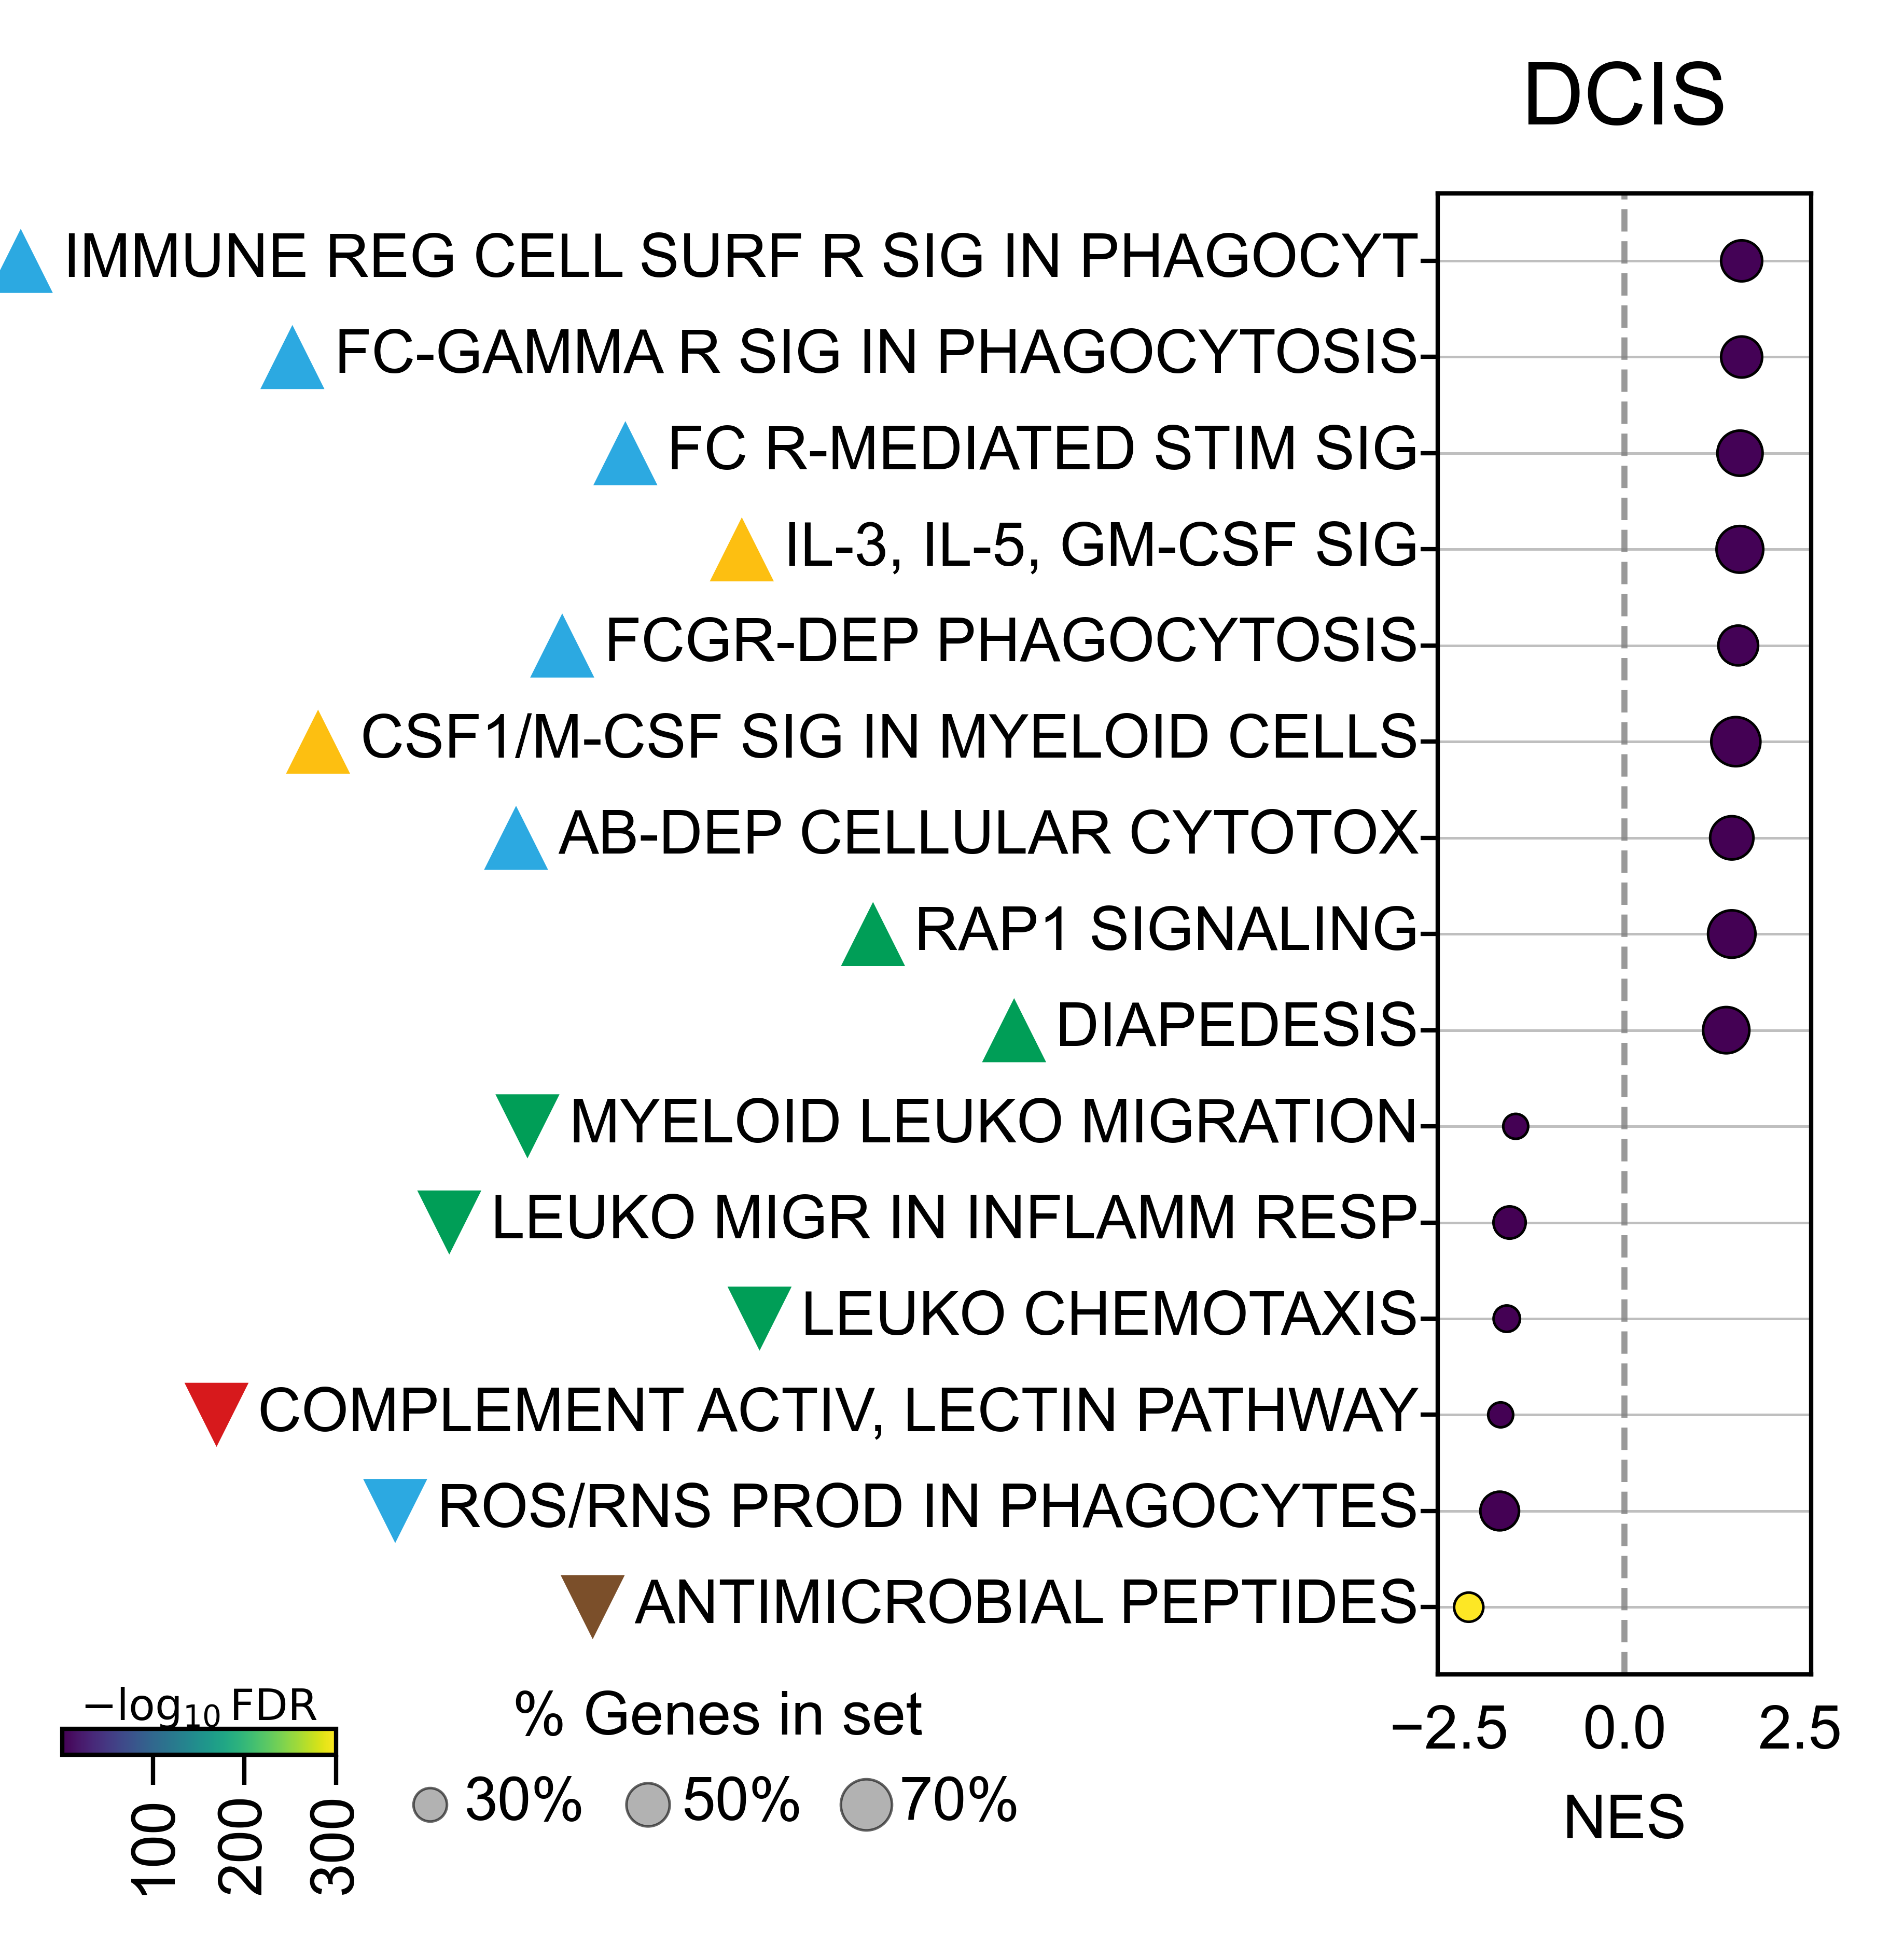

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 30
triangle_size = 55
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 3.5))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.68, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()

label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F5/Bubble_Mono_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### BC

In [20]:
DzState, db = 'BC', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['INTERFERON ALPHA/BETA SIGNALING', 'LYMPHOCYTE COSTIMULATION',
       'T CELL COSTIMULATION', 'B CELL DIFFERENTIATION',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       'NATURAL KILLER CELL ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'LEUKOCYTE MEDIATED IMMUNITY', 'B CELL ACTIVATION',
       'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'INTERFERON GAMMA SIGNALING', 'RAP1 SIGNALLING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'LYMPHOCYTE PROLIFERATION', 'TOLERANCE INDUCTION',
       'ANTIVIRAL INNATE IMMUNE RESPONSE', 'COMPLEMENT CASCADE',
       'T CELL PROLIFERATION',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
       'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'ANT

In [21]:
paths_relevant = [
'INTERFERON ALPHA/BETA SIGNALING', 
    # 'LYMPHOCYTE COSTIMULATION',
    #    'T CELL COSTIMULATION', 
    # 'B CELL DIFFERENTIATION',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       # 'NATURAL KILLER CELL ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'LEUKOCYTE MEDIATED IMMUNITY', 
    # 'B CELL ACTIVATION',
       # 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'INTERFERON GAMMA SIGNALING', 
    'RAP1 SIGNALLING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       # 'LYMPHOCYTE PROLIFERATION', 
    # 'TOLERANCE INDUCTION',
       'ANTIVIRAL INNATE IMMUNE RESPONSE', 
    'COMPLEMENT CASCADE',
       # 'T CELL PROLIFERATION',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'ALPHA-BETA T CELL ACTIVATION',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       # 'ADAPTIVE IMMUNE RESPONSE BASED ON SOMATIC RECOMBINATION OF IMMUNE RECEPTORS BUILT FROM IMMUNOGLOBULIN SUPERFAMILY DOMAINS',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'COSTIMULATION BY THE CD28 FAMILY',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'DAP12 INTERACTIONS', 
    # 'NEUTROPHIL DEGRANULATION',
       'ANTIVIRAL MECHANISM BY IFN-STIMULATED GENES',
       # 'NATURAL KILLER CELL DIFFERENTIATION',
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       # 'T CELL MEDIATED CYTOTOXICITY', 
    'INTERLEUKIN-2 FAMILY SIGNALING',
       'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
       'LEUKOCYTE HOMEOSTASIS', 
    # 'TCR SIGNALING',
       'FC EPSILON RECEPTOR (FCERI) SIGNALING',
       'C-TYPE LECTIN RECEPTORS (CLRS)',
       # 'INNATE IMMUNE RESPONSE IN MUCOSA', 
    'ANTIMICROBIAL PEPTIDES',
       'ANTIMICROBIAL HUMORAL RESPONSE'    
]

In [22]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/Mono_{DzState}.csv')

In [39]:
short_name_map = {
    'INTERFERON ALPHA/BETA SIGNALING':
        'IFN-ALPHA/BETA SIG',

    'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS':
        'FCGR-DEP PHAGOCYTOSIS',

    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        'NEG REG OF IMMUNE RESP',

    'LEUKOCYTE MEDIATED CYTOTOXICITY':
        'LEUKO MEDIATED CYTOTOX',

    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        'IMMUNOREG BET LYMPHOID-NON-LYMPHOID',

    'LEUKOCYTE MEDIATED IMMUNITY':
        'LEUKO MEDIATED IMMUNITY',

    'INTERFERON GAMMA SIGNALING':
        'IFN-GAMMA SIG',

    'RAP1 SIGNALLING':
        'RAP1 SIGNALING',

    'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY':
        'FC R-MEDIATED STIM SIG',

    'ANTIVIRAL INNATE IMMUNE RESPONSE':
        'ANTIVIRAL INNATE IMMUNE RESP',

    'COMPLEMENT CASCADE':
        'COMPLEMENT CASCADE',

    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        'NEG REG OF LEUKO ACTIV',

    'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS':
        'NEG REG OF IMMUNE EFFECTOR PROCESS',

    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        'AG R-MEDIATED SIG PATHWAY',

    'ALPHA-BETA T CELL ACTIVATION':
        'ALPHA-BETA T CELL ACTIV',

    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        'FC-GAMMA R SIG IN PHAGOCYTOSIS',

    'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        'IMMUNE REG CELL SURF R SIG IN PHAGOCYT',

    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'LEUKO ACTIV IN IMMUNE RESP',

    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING':
        'IL-3, IL-5, GM-CSF SIG',

    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        'CELL ACTIV IN IMMUNE RESP',

    'DAP12 INTERACTIONS':
        'DAP12 INTERACTIONS',

    'ANTIVIRAL MECHANISM BY IFN-STIMULATED GENES':
        'ANTIVIRAL IFN-STIM GENES',

    'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS':
        'CSF1/M-CSF SIG IN MYELOID CELLS',

    'INTERLEUKIN-2 FAMILY SIGNALING':
        'IL-2 FAMILY SIG',

    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY':
        'INNATE RESP-ACTIV SIG PATHWAY',

    'LEUKOCYTE HOMEOSTASIS':
        'LEUKO HOMEOSTASIS',

    'FC EPSILON RECEPTOR (FCERI) SIGNALING':
        'FCERI SIG',

    'C-TYPE LECTIN RECEPTORS (CLRS)':
        'C-TYPE LECTIN RECEPTORS',

    'ANTIMICROBIAL PEPTIDES':
        'ANTIMICROBIAL PEPTIDES',

    'ANTIMICROBIAL HUMORAL RESPONSE':
        'ANTIMICROBIAL HUMORAL RESP'
}

In [40]:
triangle_map = {
    'INTERFERON ALPHA/BETA SIGNALING':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis

    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        {"marker": "^", "color": "#000000"},  # black; Immunoregulatory

    'LEUKOCYTE MEDIATED CYTOTOXICITY':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related / APC-lymphoid interaction

    'LEUKOCYTE MEDIATED IMMUNITY':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'INTERFERON GAMMA SIGNALING':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'RAP1 SIGNALLING':
        {"marker": "^", "color": "#009E57"},  # green; Migration / chemotaxis

    'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis / FcR-mediated uptake

    'ANTIVIRAL INNATE IMMUNE RESPONSE':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'COMPLEMENT CASCADE':
        {"marker": "^", "color": "#D7191C"},  # red; Complement

    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        {"marker": "^", "color": "#000000"},  # black; Immunoregulatory

    'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS':
        {"marker": "^", "color": "#000000"},  # black; Immunoregulatory

    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related

    'ALPHA-BETA T CELL ACTIVATION':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation / T-cell interaction related

    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis

    'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        {"marker": "^", "color": "#2CA9E1"},  # blue; Phagocytosis

    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival

    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'DAP12 INTERACTIONS':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'ANTIVIRAL MECHANISM BY IFN-STIMULATED GENES':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival

    'INTERLEUKIN-2 FAMILY SIGNALING':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY':
        {"marker": "^", "color": "#5E4FA2"},  # purple; Inflammatory / priming

    'LEUKOCYTE HOMEOSTASIS':
        {"marker": "^", "color": "#FDBF11"},  # yellow; Mobilization / survival

    'FC EPSILON RECEPTOR (FCERI) SIGNALING':
        {"marker": "^", "color": "#F46D1F"},  # orange; Antigen presentation related / FcR-mediated antigen uptake

    'C-TYPE LECTIN RECEPTORS (CLRS)':
        {"marker": "^", "color": "#7B4F2A"},  # brown; Antimicrobial response / microbial pattern recognition

    'ANTIMICROBIAL PEPTIDES':
        {"marker": "v", "color": "#7B4F2A"},  # brown; Antimicrobial response

    'ANTIMICROBIAL HUMORAL RESPONSE':
        {"marker": "v", "color": "#7B4F2A"}   # brown; Antimicrobial response
}

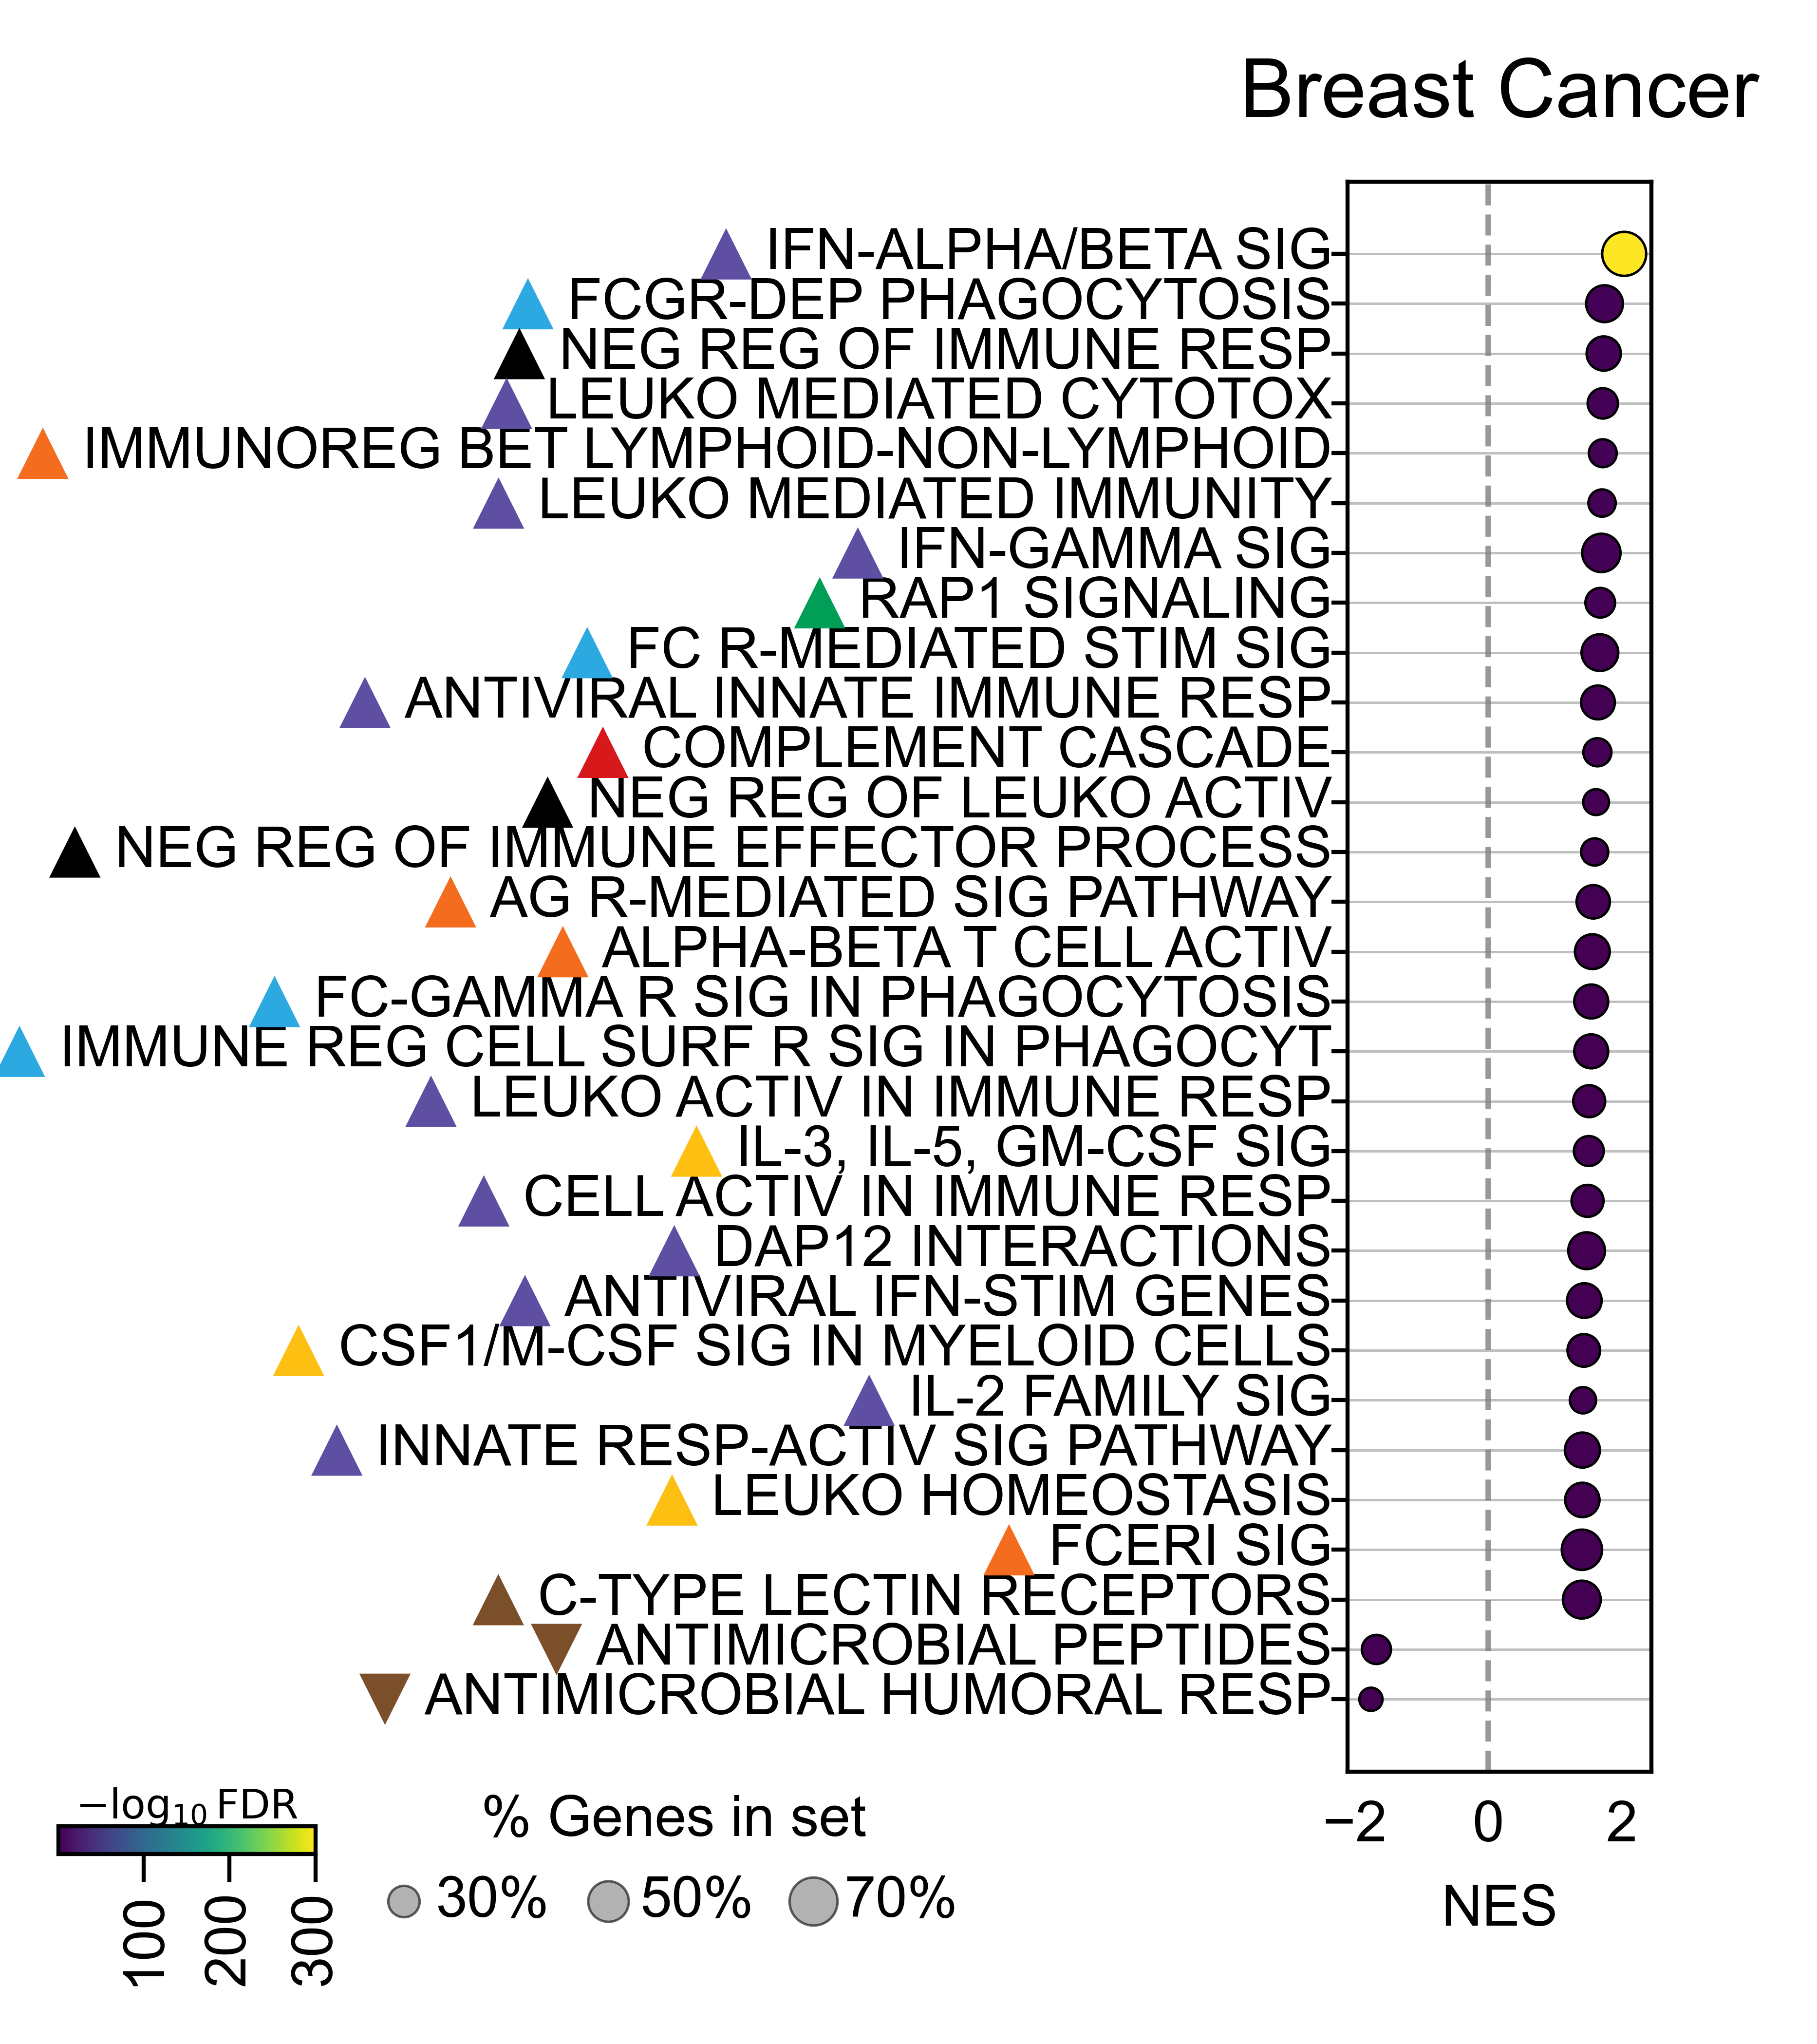

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 30
triangle_size = 40
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 4))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.72, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()

label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F5/Bubble_Mono_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### find overlaps

In [27]:
t1 = [
    # 'T CELL PROLIFERATION', 
    'ANTIVIRAL INNATE IMMUNE RESPONSE',
    # 'LYMPHOCYTE PROLIFERATION', 
    'INTERFERON ALPHA/BETA SIGNALING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       # 'NATURAL KILLER CELL ACTIVATION', 
    'RAP1 SIGNALLING',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       # 'T CELL COSTIMULATION', 
    # 'B CELL ACTIVATION',
       # 'LYMPHOCYTE COSTIMULATION',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
    #    'B CELL DIFFERENTIATION', 
    # 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'COSTIMULATION BY THE CD28 FAMILY',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE', 
    'DIAPEDESIS',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'LEUKOCYTE HOMEOSTASIS',
       'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
       'FLT3 SIGNALING', 
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'LEUKOCYTE MEDIATED IMMUNITY', 
    'INTERLEUKIN-2 FAMILY SIGNALING',
       # 'TOLERANCE INDUCTION', 
    'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       # 'HUMORAL IMMUNE RESPONSE MEDIATED BY CIRCULATING IMMUNOGLOBULIN',
       'MYELOID LEUKOCYTE MIGRATION', 
       'LEUKOCYTE CHEMOTAXIS',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
       # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'ANTIMICROBIAL PEPTIDES', 
    # 'INNATE IMMUNE RESPONSE IN MUCOSA',
       'ANTIMICROBIAL HUMORAL RESPONSE'
]

t2 = [
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS', 
       'FLT3 SIGNALING',
       # 'B CELL DIFFERENTIATION',
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       # 'NATURAL KILLER CELL ACTIVATION', 
    # 'B CELL ACTIVATION',
    #    'T CELL COSTIMULATION', 
    # 'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
       'RAP1 SIGNALLING', 
    # 'LYMPHOCYTE COSTIMULATION',
       'INTERLEUKIN-2 FAMILY SIGNALING',
       'COSTIMULATION BY THE CD28 FAMILY',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'LYMPHOCYTE PROLIFERATION',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY', 
    'DIAPEDESIS',
    #    'T CELL PROLIFERATION', 
    # 'GROWTH HORMONE RECEPTOR SIGNALING',
    #    'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       # 'NATURAL KILLER CELL DIFFERENTIATION',
       # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'TOLERANCE INDUCTION', 
    'MYELOID LEUKOCYTE MIGRATION',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'LEUKOCYTE CHEMOTAXIS', 
    'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       # 'INNATE IMMUNE RESPONSE IN MUCOSA',
       'ANTIMICROBIAL HUMORAL RESPONSE', 
    'ANTIMICROBIAL PEPTIDES'
]

t3 = [
'INTERFERON ALPHA/BETA SIGNALING', 
    # 'LYMPHOCYTE COSTIMULATION',
    #    'T CELL COSTIMULATION', 
    # 'B CELL DIFFERENTIATION',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       # 'NATURAL KILLER CELL ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'LEUKOCYTE MEDIATED IMMUNITY', 
    # 'B CELL ACTIVATION',
       # 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'INTERFERON GAMMA SIGNALING', 
    'RAP1 SIGNALLING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       # 'LYMPHOCYTE PROLIFERATION', 
    # 'TOLERANCE INDUCTION',
       'ANTIVIRAL INNATE IMMUNE RESPONSE', 
    'COMPLEMENT CASCADE',
       # 'T CELL PROLIFERATION',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'ALPHA-BETA T CELL ACTIVATION',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       # 'ADAPTIVE IMMUNE RESPONSE BASED ON SOMATIC RECOMBINATION OF IMMUNE RECEPTORS BUILT FROM IMMUNOGLOBULIN SUPERFAMILY DOMAINS',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'COSTIMULATION BY THE CD28 FAMILY',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'DAP12 INTERACTIONS', 
    # 'NEUTROPHIL DEGRANULATION',
       'ANTIVIRAL MECHANISM BY IFN-STIMULATED GENES',
       # 'NATURAL KILLER CELL DIFFERENTIATION',
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       # 'T CELL MEDIATED CYTOTOXICITY', 
    'INTERLEUKIN-2 FAMILY SIGNALING',
       'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
       'LEUKOCYTE HOMEOSTASIS', 
    # 'TCR SIGNALING',
       'FC EPSILON RECEPTOR (FCERI) SIGNALING',
       'C-TYPE LECTIN RECEPTORS (CLRS)',
       # 'INNATE IMMUNE RESPONSE IN MUCOSA', 
    'ANTIMICROBIAL PEPTIDES',
       'ANTIMICROBIAL HUMORAL RESPONSE'    
]

In [37]:
# re-filtered
t1 = {
     # 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
     # 'ANTIMICROBIAL HUMORAL RESPONSE',
     # 'ANTIMICROBIAL PEPTIDES',
     'ANTIVIRAL INNATE IMMUNE RESPONSE',
     'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
     'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',
     'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
     'DIAPEDESIS',
     'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
     'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
     'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
     # 'FLT3 SIGNALING',
     'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
     'INTERFERON ALPHA/BETA SIGNALING',
     # 'INTERLEUKIN-2 FAMILY SIGNALING',
     'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
     'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
     'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
     'LEUKOCYTE CHEMOTAXIS',
     'LEUKOCYTE HOMEOSTASIS',
     'LEUKOCYTE MEDIATED IMMUNITY',
     'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
     'MYELOID LEUKOCYTE MIGRATION',
     'NEGATIVE REGULATION OF IMMUNE RESPONSE',
     'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
     'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
     'RAP1 SIGNALLING',
     'ROS AND RNS PRODUCTION IN PHAGOCYTES',
     'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS'
    }

t2 = {
     # 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
     # 'ANTIMICROBIAL HUMORAL RESPONSE',
     # 'ANTIMICROBIAL PEPTIDES',
     'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
     # 'COSTIMULATION BY THE CD28 FAMILY',
     'DIAPEDESIS',
     'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
     'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
     'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
     # 'FLT3 SIGNALING',
     'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
     # 'INTERLEUKIN-2 FAMILY SIGNALING',
     'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
     'LEUKOCYTE CHEMOTAXIS',
     'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
     'MYELOID LEUKOCYTE MIGRATION',
     'RAP1 SIGNALLING',
     'ROS AND RNS PRODUCTION IN PHAGOCYTES',
     'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS'
}

t3 = {
     # 'ALPHA-BETA T CELL ACTIVATION',
     # 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
     # 'ANTIMICROBIAL HUMORAL RESPONSE',
     # 'ANTIMICROBIAL PEPTIDES',
     'ANTIVIRAL INNATE IMMUNE RESPONSE',
     'ANTIVIRAL MECHANISM BY IFN-STIMULATED GENES',
     'C-TYPE LECTIN RECEPTORS (CLRS)',
     'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
     'COMPLEMENT CASCADE',
     'DAP12 INTERACTIONS',
     # 'FC EPSILON RECEPTOR (FCERI) SIGNALING',
     'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
     'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
     'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
     'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
     'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
     'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
     'INTERFERON ALPHA/BETA SIGNALING',
     'INTERFERON GAMMA SIGNALING',
     # 'INTERLEUKIN-2 FAMILY SIGNALING',
     'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
     'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
     'LEUKOCYTE HOMEOSTASIS',
     # 'LEUKOCYTE MEDIATED CYTOTOXICITY',
     'LEUKOCYTE MEDIATED IMMUNITY',
     'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
     'NEGATIVE REGULATION OF IMMUNE RESPONSE',
     'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
     'RAP1 SIGNALLING',
     'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS'    
}

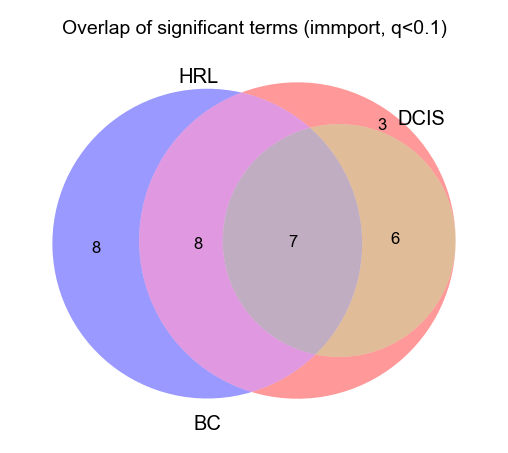

In [38]:
# t1,t2,t3 = set(t1),set(t2),set(t3)

plt.figure(figsize=(3, 3), dpi=100)
venn3([t1, t2, t3], set_labels=('HRL', 'DCIS', 'BC'))
plt.title(f'Overlap of significant terms ({db}, q<{qthres})')
plt.show()

In [42]:
regions = {
    'HRL only': sorted(t1 - t2 - t3),
    'DCIS only': sorted(t2 - t1 - t3),
    'BC only': sorted(t3 - t1 - t2),
    'HRL & DCIS only': sorted((t1 & t2) - t3),
    'HRL & BC only': sorted((t1 & t3) - t2),
    'DCIS & BC only': sorted((t2 & t3) - t1),
    'HRL & DCIS & BC': sorted(t1 & t2 & t3),
}


for k, v in regions.items():
    print(f'\n{k} ({len(v)} terms)')
    for term in v:
        print(term)


HRL only (3 terms)
COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY
INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING
NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY

DCIS only (0 terms)

BC only (8 terms)
ANTIVIRAL MECHANISM BY IFN-STIMULATED GENES
C-TYPE LECTIN RECEPTORS (CLRS)
COMPLEMENT CASCADE
DAP12 INTERACTIONS
IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL
INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY
INTERFERON GAMMA SIGNALING
NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS

HRL & DCIS only (6 terms)
COMPLEMENT ACTIVATION, LECTIN PATHWAY
DIAPEDESIS
LEUKOCYTE CHEMOTAXIS
LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE
MYELOID LEUKOCYTE MIGRATION
ROS AND RNS PRODUCTION IN PHAGOCYTES

HRL & BC only (8 terms)
ANTIVIRAL INNATE IMMUNE RESPONSE
CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE
INTERFERON ALPHA/BETA SIGNALING
LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE
LEUKOCYTE HOMEOSTASIS
LEUKOCYTE MEDIATED IMMUNITY
NEGATIVE REGULATION OF IMMUNE R